In [1]:
import os
from glob import glob
import random

In [2]:
import numpy as np
import matplotlib.pyplot as plt

In [3]:
import tensorflow as tf
from sklearn.model_selection import train_test_split

### ЗАГРУЗКА НАБОРА ДАННЫХ

In [4]:
BASE_DIR = "/Users/maryc/university/PythonProject/инструменты анализа данных/2 sem/3-7 task/carvana-image-masking-challenge"

In [5]:
TRAIN_DIR = os.path.join(BASE_DIR, "train")
MASK_DIR = os.path.join(BASE_DIR, "train_masks")

In [6]:
image_paths = sorted(glob(os.path.join(TRAIN_DIR, "*.jpg")))

In [7]:
mask_paths = []

Берем только часть данных

In [44]:
SUBSET_SIZE = 1200         
image_paths = sorted(glob(os.path.join(TRAIN_DIR, "*.jpg")))[:SUBSET_SIZE]
mask_paths = []

In [45]:
for img_path in image_paths:   # теперь итерируемся только по укороченному списку
    filename = os.path.basename(img_path)
    mask_name = filename.replace(".jpg", "_mask.gif")
    mask_path = os.path.join(MASK_DIR, mask_name)
    mask_paths.append(mask_path)

In [21]:
len(image_paths)

1200

In [22]:
len(mask_paths)

3600

проверка размеров изображений

In [23]:
sample_img = tf.io.read_file(image_paths[0])
sample_img = tf.image.decode_jpeg(sample_img, channels=3)

In [24]:
sample_mask = tf.io.read_file(mask_paths[0])
sample_mask = tf.image.decode_gif(sample_mask)[0]

In [25]:
sample_img.shape

TensorShape([1280, 1918, 3])

In [26]:
sample_mask.shape

TensorShape([1280, 1918, 3])

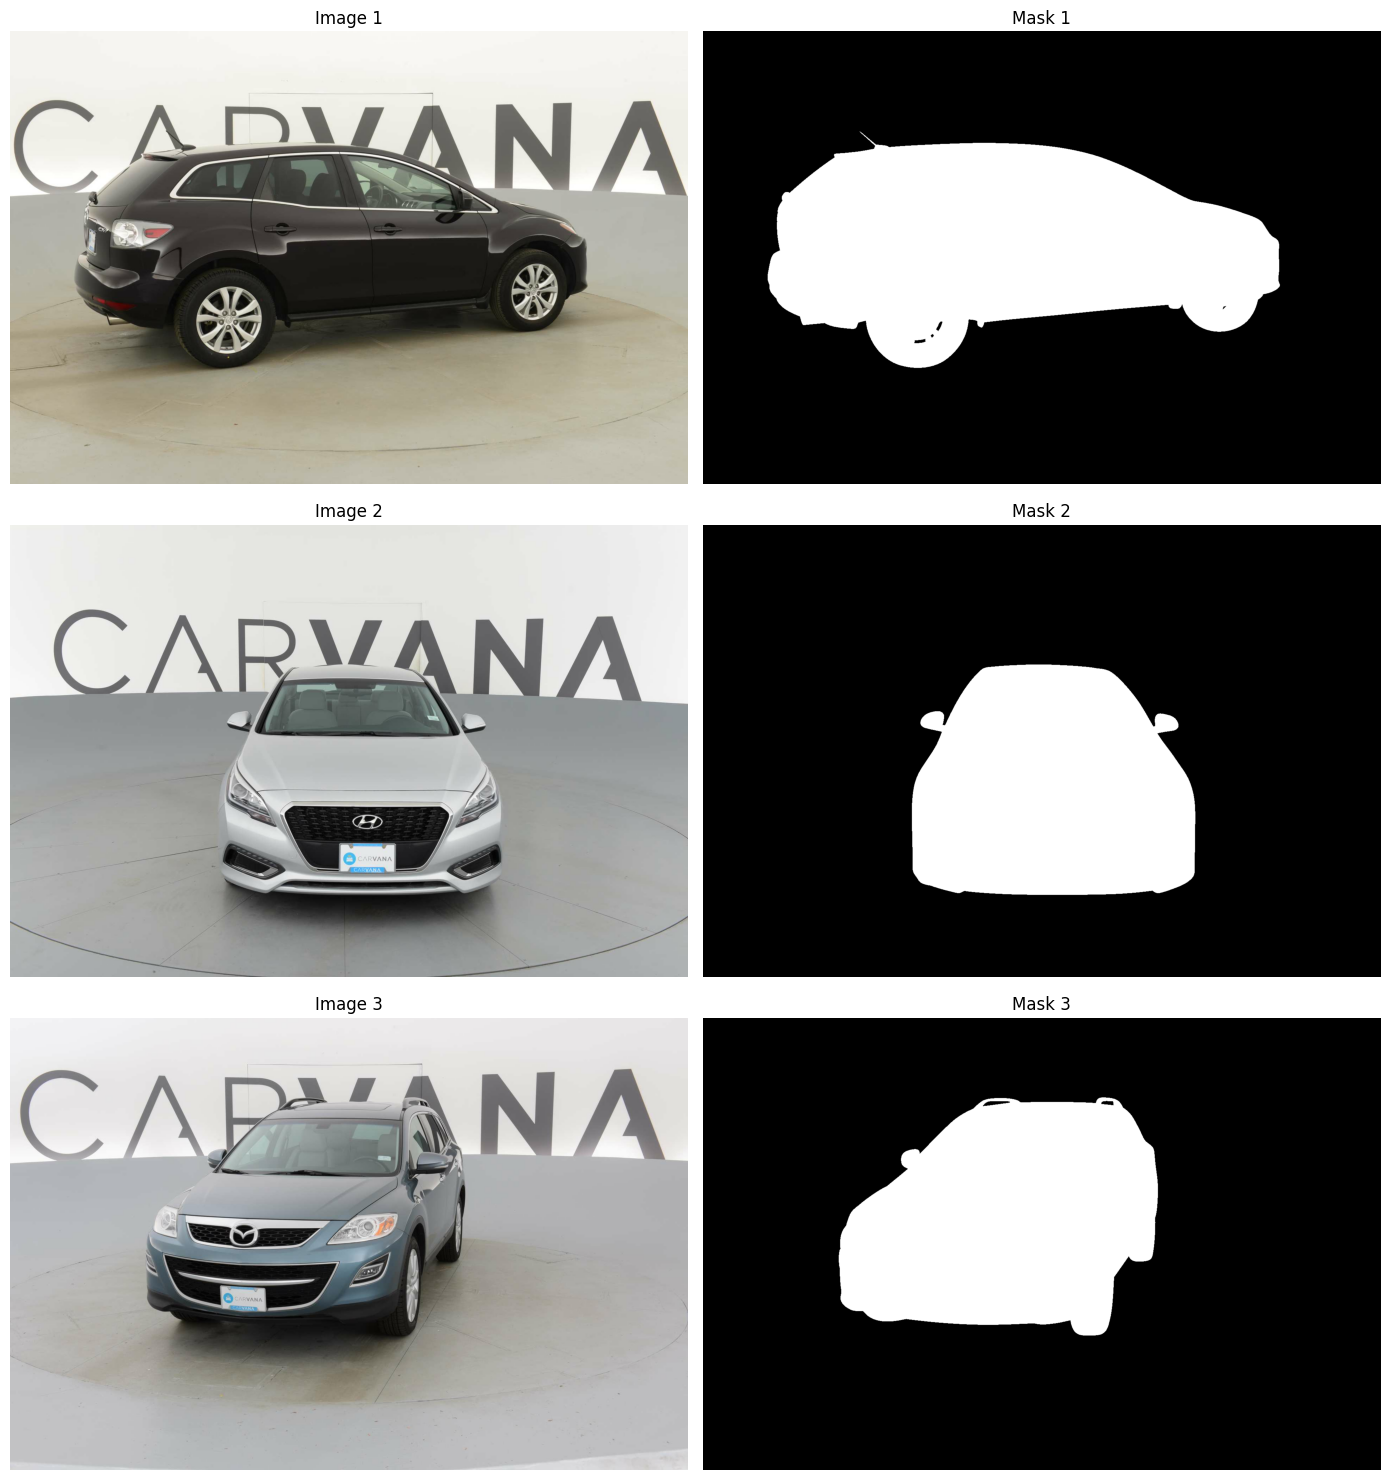

In [27]:
def show_samples(image_paths, mask_paths, n=3):

    plt.figure(figsize=(14, 5 * n))

    for i in range(n):

        idx = random.randint(0, len(image_paths) - 1)

        # IMAGE
        img = tf.io.read_file(image_paths[idx])
        img = tf.image.decode_jpeg(img, channels=3)

        # MASK
        mask = tf.io.read_file(mask_paths[idx])
        mask = tf.image.decode_gif(mask)[0]

        # IMAGE
        plt.subplot(n, 2, 2 * i + 1)
        plt.imshow(img.numpy())
        plt.title(f"Image {i+1}")
        plt.axis("off")

        # MASK
        plt.subplot(n, 2, 2 * i + 2)
        plt.imshow(mask.numpy().squeeze(), cmap="gray")
        plt.title(f"Mask {i+1}")
        plt.axis("off")

    plt.tight_layout()
    plt.show()

show_samples(image_paths, mask_paths)

### Предобработка данных

In [16]:
IMG_SIZE = (256, 256)

In [ ]:
def load_image_mask(img_path, mask_path):

    # ЗАГРУЗКА ИЗОБРАЖЕНИЯ

    image = tf.io.read_file(img_path)

    image = tf.image.decode_jpeg(
        image,
        channels=3
    )

    # уменьшение размера
    image = tf.image.resize(
        image,
        IMG_SIZE
    )

    # нормализация [0;1]
    image = tf.cast(image, tf.float32) / 255.0

    # ЗАГРУЗКА МАСКИ

    mask = tf.io.read_file(mask_path)

    # GIF то берем первый кадр
    mask = tf.image.decode_gif(mask)[0]

    # resize
    mask = tf.image.resize(
        mask,
        IMG_SIZE,
        method="nearest"
    )

    # нормализация
    mask = tf.cast(mask, tf.float32) / 255.0

    # бинаризация маски
    mask = tf.where(mask > 0.5, 1.0, 0.0)

    return image, mask

In [28]:
IMG_HEIGHT = 128
IMG_WIDTH = 128

In [32]:
def load_image_mask(img_path, mask_path):
    # image
    img = tf.io.read_file(img_path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, [IMG_HEIGHT, IMG_WIDTH])
    img = tf.cast(img, tf.float32) / 255.0
    
    # mask
    mask = tf.io.read_file(mask_path)
    mask = tf.image.decode_gif(mask)[0]
    mask = tf.image.resize(mask, [IMG_HEIGHT, IMG_WIDTH], method='nearest')
    mask = tf.cast(mask[..., 0:1] > 0, tf.float32)   # бинарная маска
    
    return img, mask

ПРОВЕРКА ПРЕДОБРАБОТКИ

In [33]:
image, mask = load_image_mask(
    image_paths[0],
    mask_paths[0]
)

In [34]:
image.shape

TensorShape([128, 128, 3])

In [35]:
mask.shape

TensorShape([128, 128, 1])

In [36]:
tf.reduce_min(image).numpy()

np.float32(0.007843138)

In [37]:
tf.reduce_max(image).numpy()

np.float32(1.0)

In [38]:
np.unique(mask.numpy())

array([0., 1.], dtype=float32)

### АУГМЕНТАЦИЯ

image и mask должны изменяться одинаково

In [39]:
augmenter = tf.keras.Sequential([

    # случайное горизонтальное отражение
    tf.keras.layers.RandomFlip("horizontal"),

    # небольшой поворот
    tf.keras.layers.RandomRotation(
        factor=0.05
    )

])

In [ ]:
def augment(image, mask):

    # объединяем
    combined = tf.concat(
        [image, mask],
        axis=-1
    )

    # аугментация
    combined = augmenter(
        combined,
        training=True
    )

    # image -> первые 3 канала
    image = combined[..., :3]

    # mask -> только последний канал
    mask = combined[..., 3:4]

    # бинаризация
    mask = tf.where(mask > 0.5, 1.0, 0.0)

    return image, mask

In [40]:
def augment(image, mask):
    # Случайное отражение по горизонтали
    if tf.random.uniform(()) > 0.5:
        image = tf.image.flip_left_right(image)
        mask = tf.image.flip_left_right(mask)
    
    # Небольшой поворот (±10 градусов)
    angle = tf.random.uniform((), minval=-0.17, maxval=0.17)  # ~±10°
    image = tf.image.rot90(image, k=tf.cast(angle*10, tf.int32) % 4)  # грубо, но быстро
    mask = tf.image.rot90(mask, k=tf.cast(angle*10, tf.int32) % 4)
    
    return image, mask

In [41]:
aug_image, aug_mask = augment(image, mask)

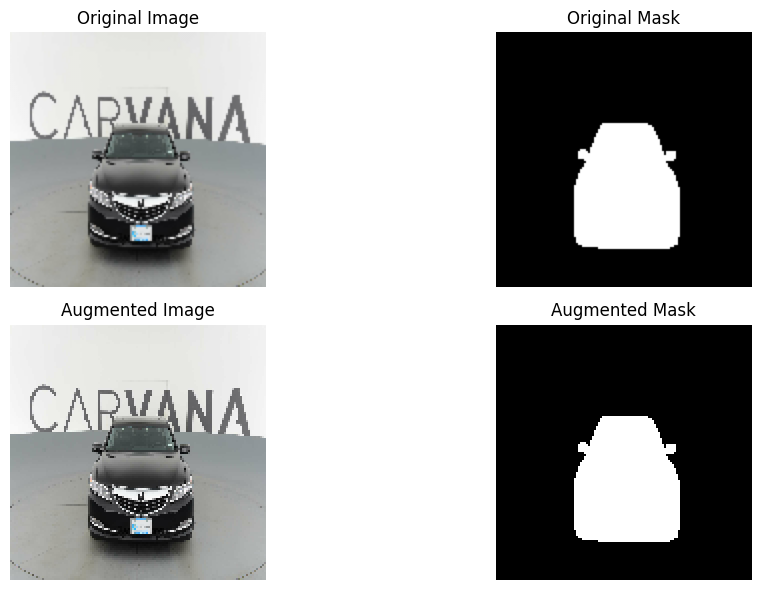

In [42]:

plt.figure(figsize=(12, 6))

# ORIGINAL IMAGE
plt.subplot(2, 2, 1)
plt.imshow(image.numpy())
plt.title("Original Image")
plt.axis("off")

# ORIGINAL MASK
plt.subplot(2, 2, 2)
plt.imshow(mask.numpy().squeeze(), cmap="gray")
plt.title("Original Mask")
plt.axis("off")

# AUGMENTED IMAGE
plt.subplot(2, 2, 3)
plt.imshow(aug_image.numpy())
plt.title("Augmented Image")
plt.axis("off")

# AUGMENTED MASK
plt.subplot(2, 2, 4)
plt.imshow(aug_mask.numpy().squeeze(), cmap="gray")
plt.title("Augmented Mask")
plt.axis("off")

plt.tight_layout()
plt.show()

### TRAIN / VALIDATION SPLIT

In [46]:
train_images, val_images, train_masks, val_masks = train_test_split(
    image_paths,
    mask_paths,
    test_size=0.2,
    random_state=42
)

In [47]:
len(train_images)

960

In [48]:
len(val_images)

240

### СОЗДАНИЕ TF.DATA DATASET

In [49]:
BATCH_SIZE = 8
AUTOTUNE = tf.data.AUTOTUNE

In [50]:
def create_dataset(images, masks, training=False):

    dataset = tf.data.Dataset.from_tensor_slices(
        (images, masks)
    )

    # загрузка и preprocessing
    dataset = dataset.map(
        load_image_mask,
        num_parallel_calls=AUTOTUNE
    )

    # аугментация только для train
    if training:

        dataset = dataset.shuffle(512)

        dataset = dataset.map(
            augment,
            num_parallel_calls=AUTOTUNE
        )

    # batching
    dataset = dataset.batch(BATCH_SIZE)

    # prefetch
    dataset = dataset.prefetch(AUTOTUNE)

    return dataset

In [51]:
train_dataset = create_dataset(
    train_images,
    train_masks,
    training=True
)

In [52]:
val_dataset = create_dataset(
    val_images,
    val_masks,
    training=False
)


Batch image shape: (8, 128, 128, 3)
Batch mask shape: (8, 128, 128, 1)


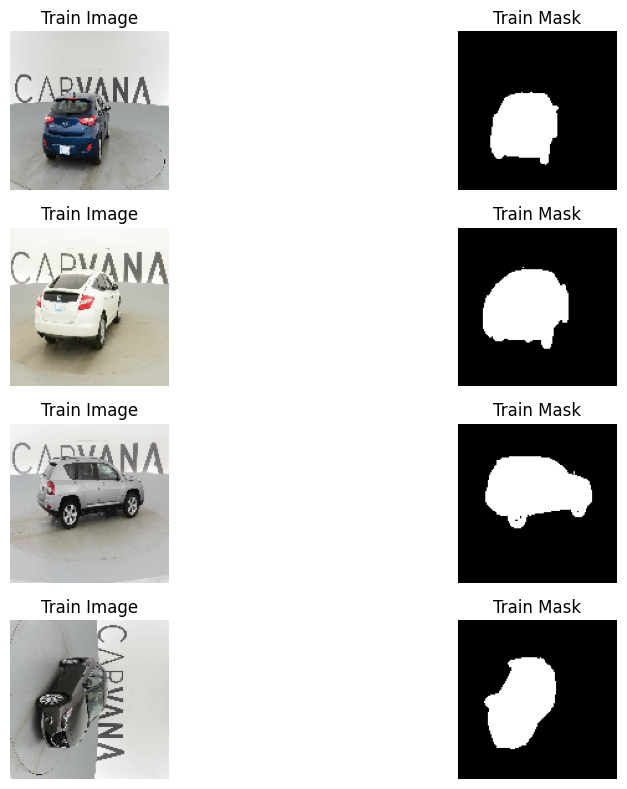

In [53]:
for batch_images, batch_masks in train_dataset.take(1):

    print("\nBatch image shape:",
          batch_images.shape)

    print("Batch mask shape:",
          batch_masks.shape)

    # визуализация батча
    plt.figure(figsize=(12, 8))

    for i in range(4):

        # IMAGE
        plt.subplot(4, 2, 2 * i + 1)
        plt.imshow(batch_images[i].numpy())
        plt.title("Train Image")
        plt.axis("off")

        # MASK
        plt.subplot(4, 2, 2 * i + 2)
        plt.imshow(
            batch_masks[i].numpy().squeeze(),
            cmap="gray"
        )
        plt.title("Train Mask")
        plt.axis("off")

    plt.tight_layout()
    plt.show()

### ОБУЧЕНИЕ U-NET

In [54]:
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt
import numpy as np


МЕТРИКИ

In [55]:
SMOOTH = 1e-6

Dice Coefficient

In [56]:
def dice_coef(y_true, y_pred):

    y_true = tf.cast(y_true, tf.float32)

    # бинаризация предсказания
    y_pred = tf.cast(y_pred > 0.5, tf.float32)

    intersection = tf.reduce_sum(y_true * y_pred)

    union = (
        tf.reduce_sum(y_true)
        + tf.reduce_sum(y_pred)
    )

    dice = (
        2.0 * intersection + SMOOTH
    ) / (
        union + SMOOTH
    )

    return dice

IoU (Intersection over Union)

In [57]:
def iou_coef(y_true, y_pred):

    y_true = tf.cast(y_true, tf.float32)

    y_pred = tf.cast(y_pred > 0.5, tf.float32)

    intersection = tf.reduce_sum(y_true * y_pred)

    union = (
        tf.reduce_sum(y_true)
        + tf.reduce_sum(y_pred)
        - intersection
    )

    iou = (
        intersection + SMOOTH
    ) / (
        union + SMOOTH
    )

    return iou

ФУНКЦИИ ПОТЕРЬ

In [58]:
bce_loss = tf.keras.losses.BinaryCrossentropy()


In [59]:
def dice_loss(y_true, y_pred):

    y_true = tf.cast(y_true, tf.float32)

    intersection = tf.reduce_sum(
        y_true * y_pred
    )

    union = (
        tf.reduce_sum(y_true)
        + tf.reduce_sum(y_pred)
    )

    dice = (
        2.0 * intersection + SMOOTH
    ) / (
        union + SMOOTH
    )

    return 1.0 - dice

In [60]:
def bce_dice_loss(y_true, y_pred):

    bce = bce_loss(y_true, y_pred)

    d_loss = dice_loss(y_true, y_pred)

    return bce + d_loss


U-NET

In [61]:
def conv_block(x, filters):

    x = layers.Conv2D(
        filters,
        3,
        padding="same"
    )(x)

    x = layers.BatchNormalization()(x)

    x = layers.Activation("relu")(x)

    x = layers.Conv2D(
        filters,
        3,
        padding="same"
    )(x)

    x = layers.BatchNormalization()(x)

    x = layers.Activation("relu")(x)

    return x

In [ ]:
def build_unet(input_shape=(256, 256, 3)):

    inputs = layers.Input(input_shape)

    # ENCODER

    c1 = conv_block(inputs, 64)
    p1 = layers.MaxPooling2D()(c1)

    c2 = conv_block(p1, 128)
    p2 = layers.MaxPooling2D()(c2)

    c3 = conv_block(p2, 256)
    p3 = layers.MaxPooling2D()(c3)

    c4 = conv_block(p3, 512)
    p4 = layers.MaxPooling2D()(c4)

    # BOTTLENECK

    bn = conv_block(p4, 1024)

    # DECODER

    u1 = layers.Conv2DTranspose(
        512,
        2,
        strides=2,
        padding="same"
    )(bn)

    u1 = layers.Concatenate()([u1, c4])

    c5 = conv_block(u1, 512)

    u2 = layers.Conv2DTranspose(
        256,
        2,
        strides=2,
        padding="same"
    )(c5)

    u2 = layers.Concatenate()([u2, c3])

    c6 = conv_block(u2, 256)

    u3 = layers.Conv2DTranspose(
        128,
        2,
        strides=2,
        padding="same"
    )(c6)

    u3 = layers.Concatenate()([u3, c2])

    c7 = conv_block(u3, 128)

    u4 = layers.Conv2DTranspose(
        64,
        2,
        strides=2,
        padding="same"
    )(c7)

    u4 = layers.Concatenate()([u4, c1])

    c8 = conv_block(u4, 64)

    outputs = layers.Conv2D(
        1,
        1,
        activation="sigmoid"
    )(c8)

    model = models.Model(inputs, outputs)

    return model

In [65]:
def build_unet(input_shape=(128, 128, 3)):
    inputs = layers.Input(input_shape)
    
    # Encoder
    c1 = conv_block(inputs, 32)
    p1 = layers.MaxPooling2D()(c1)
    
    c2 = conv_block(p1, 64)
    p2 = layers.MaxPooling2D()(c2)
    
    c3 = conv_block(p2, 128)
    p3 = layers.MaxPooling2D()(c3)
    
    # Bottleneck
    bn = conv_block(p3, 256)
    
    # Decoder
    u1 = layers.Conv2DTranspose(128, 2, strides=2, padding="same")(bn)
    u1 = layers.Concatenate()([u1, c3])
    c4 = conv_block(u1, 128)
    
    u2 = layers.Conv2DTranspose(64, 2, strides=2, padding="same")(c4)
    u2 = layers.Concatenate()([u2, c2])
    c5 = conv_block(u2, 64)
    
    u3 = layers.Conv2DTranspose(32, 2, strides=2, padding="same")(c5)
    u3 = layers.Concatenate()([u3, c1])
    c6 = conv_block(u3, 32)
    
    outputs = layers.Conv2D(1, 1, activation="sigmoid")(c6)
    
    return models.Model(inputs, outputs)

In [66]:
callbacks = [

    tf.keras.callbacks.EarlyStopping(
        patience=5,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        patience=3,
        factor=0.5
    )

]

In [67]:
model_bce = build_unet()

In [68]:
model_bce.compile(

    optimizer=tf.keras.optimizers.Adam(1e-4),

    loss=bce_loss,

    metrics=[
        dice_coef,
        iou_coef
    ]

)

In [69]:
history_bce = model_bce.fit(

    train_dataset,

    validation_data=val_dataset,

    epochs=20,

    callbacks=callbacks

)

Epoch 1/20
120/120 ━━━━━━━━━━━━━━━━━━━━ 63s 489ms/step - dice_coef: 0.8443 - iou_coef: 0.7499 - loss: 0.2684 - val_dice_coef: 3.6738e-11 - val_iou_coef: 3.6738e-11 - val_loss: 0.5121 - learning_rate: 1.0000e-04
Epoch 2/20
120/120 ━━━━━━━━━━━━━━━━━━━━ 66s 532ms/step - dice_coef: 0.9508 - iou_coef: 0.9063 - loss: 0.1275 - val_dice_coef: 3.6738e-11 - val_iou_coef: 3.6738e-11 - val_loss: 0.5307 - learning_rate: 1.0000e-04
Epoch 3/20
120/120 ━━━━━━━━━━━━━━━━━━━━ 76s 617ms/step - dice_coef: 0.9595 - iou_coef: 0.9223 - loss: 0.1028 - val_dice_coef: 0.0470 - val_iou_coef: 0.0243 - val_loss: 0.5322 - learning_rate: 1.0000e-04
Epoch 4/20
120/120 ━━━━━━━━━━━━━━━━━━━━ 64s 516ms/step - dice_coef: 0.9658 - iou_coef: 0.9338 - loss: 0.0861 - val_dice_coef: 0.8830 - val_iou_coef: 0.7912 - val_loss: 0.1384 - learning_rate: 1.0000e-04
Epoch 5/20
120/120 ━━━━━━━━━━━━━━━━━━━━ 70s 566ms/step - dice_coef: 0.9678 - iou_coef: 0.9377 - loss: 0.0758 - val_dice_coef: 0.9521 - val_iou_coef: 0.9086 - val_loss: 0.07

ОБУЧЕНИЕ С DICE LOSS

In [70]:
model_dice = build_unet()

In [71]:
model_dice.compile(

    optimizer=tf.keras.optimizers.Adam(1e-4),

    loss=dice_loss,

    metrics=[
        dice_coef,
        iou_coef
    ]

)

In [72]:
history_dice = model_dice.fit(

    train_dataset,

    validation_data=val_dataset,

    epochs=20,

    callbacks=callbacks

)

Epoch 1/20
120/120 ━━━━━━━━━━━━━━━━━━━━ 98s 774ms/step - dice_coef: 0.7712 - iou_coef: 0.6471 - loss: 0.3914 - val_dice_coef: 3.6738e-11 - val_iou_coef: 3.6738e-11 - val_loss: 0.7532 - learning_rate: 1.0000e-04
Epoch 2/20
120/120 ━━━━━━━━━━━━━━━━━━━━ 83s 674ms/step - dice_coef: 0.9255 - iou_coef: 0.8618 - loss: 0.2750 - val_dice_coef: 3.6738e-11 - val_iou_coef: 3.6738e-11 - val_loss: 0.7979 - learning_rate: 1.0000e-04
Epoch 3/20
120/120 ━━━━━━━━━━━━━━━━━━━━ 86s 696ms/step - dice_coef: 0.9474 - iou_coef: 0.9002 - loss: 0.2385 - val_dice_coef: 0.1578 - val_iou_coef: 0.0867 - val_loss: 0.7495 - learning_rate: 1.0000e-04
Epoch 4/20
120/120 ━━━━━━━━━━━━━━━━━━━━ 84s 681ms/step - dice_coef: 0.9575 - iou_coef: 0.9186 - loss: 0.2152 - val_dice_coef: 0.7761 - val_iou_coef: 0.6367 - val_loss: 0.3691 - learning_rate: 5.0000e-05
Epoch 5/20
120/120 ━━━━━━━━━━━━━━━━━━━━ 82s 668ms/step - dice_coef: 0.9616 - iou_coef: 0.9261 - loss: 0.2007 - val_dice_coef: 0.9683 - val_iou_coef: 0.9385 - val_loss: 0.20

ОБУЧЕНИЕ С BCE + DICE LOSS

In [73]:
model_combined = build_unet()

In [74]:
model_combined.compile(

    optimizer=tf.keras.optimizers.Adam(1e-4),

    loss=bce_dice_loss,

    metrics=[
        dice_coef,
        iou_coef
    ]

)

In [75]:
history_combined = model_combined.fit(

    train_dataset,

    validation_data=val_dataset,

    epochs=20,

    callbacks=callbacks

)

Epoch 1/20
120/120 ━━━━━━━━━━━━━━━━━━━━ 85s 671ms/step - dice_coef: 0.8349 - iou_coef: 0.7437 - loss: 0.6076 - val_dice_coef: 3.6738e-11 - val_iou_coef: 3.6738e-11 - val_loss: 1.2943 - learning_rate: 1.0000e-04
Epoch 2/20
120/120 ━━━━━━━━━━━━━━━━━━━━ 98s 798ms/step - dice_coef: 0.9535 - iou_coef: 0.9114 - loss: 0.2914 - val_dice_coef: 3.6738e-11 - val_iou_coef: 3.6738e-11 - val_loss: 1.3525 - learning_rate: 1.0000e-04
Epoch 3/20
120/120 ━━━━━━━━━━━━━━━━━━━━ 85s 692ms/step - dice_coef: 0.9628 - iou_coef: 0.9283 - loss: 0.2352 - val_dice_coef: 0.2802 - val_iou_coef: 0.1646 - val_loss: 1.1084 - learning_rate: 1.0000e-04
Epoch 4/20
120/120 ━━━━━━━━━━━━━━━━━━━━ 86s 699ms/step - dice_coef: 0.9678 - iou_coef: 0.9377 - loss: 0.2050 - val_dice_coef: 0.9420 - val_iou_coef: 0.8904 - val_loss: 0.2581 - learning_rate: 5.0000e-05
Epoch 5/20
120/120 ━━━━━━━━━━━━━━━━━━━━ 86s 700ms/step - dice_coef: 0.9705 - iou_coef: 0.9427 - loss: 0.1876 - val_dice_coef: 0.9725 - val_iou_coef: 0.9466 - val_loss: 0.17

### Оценка и визуализация результатов

In [76]:
import pandas as pd


In [77]:

def plot_history(history, title):
    fig, axes = plt.subplots(1, 3, figsize=(18, 4))

    axes[0].plot(history.history["loss"], label="train")
    axes[0].plot(history.history["val_loss"], label="val")
    axes[0].set_title(f"{title} — Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].legend()

    if "dice_coef" in history.history:
        axes[1].plot(history.history["dice_coef"], label="train")
        axes[1].plot(history.history["val_dice_coef"], label="val")
        axes[1].set_title(f"{title} — Dice")
        axes[1].set_xlabel("Epoch")
        axes[1].legend()

    if "iou_coef" in history.history:
        axes[2].plot(history.history["iou_coef"], label="train")
        axes[2].plot(history.history["val_iou_coef"], label="val")
        axes[2].set_title(f"{title} — IoU")
        axes[2].set_xlabel("Epoch")
        axes[2].legend()

    plt.tight_layout()
    plt.show()

In [78]:
def evaluate_model(model, dataset, name):
    loss, dice, iou = model.evaluate(dataset, verbose=0)
    return {
        "model": name,
        "loss": float(loss),
        "dice_coef": float(dice),
        "iou_coef": float(iou),
    }

In [79]:
def show_predictions(model, dataset, n=3):
    for images, masks in dataset.take(1):
        preds = model.predict(images, verbose=0)

        n = min(n, images.shape[0])
        plt.figure(figsize=(16, 5 * n))

        for i in range(n):
            img = images[i].numpy()
            true_mask = masks[i].numpy().squeeze()
            pred_mask = (preds[i].squeeze() > 0.5).astype(np.float32)

            plt.subplot(n, 3, 3 * i + 1)
            plt.imshow(img)
            plt.title("Image")
            plt.axis("off")

            plt.subplot(n, 3, 3 * i + 2)
            plt.imshow(true_mask, cmap="gray")
            plt.title("True mask")
            plt.axis("off")

            plt.subplot(n, 3, 3 * i + 3)
            plt.imshow(pred_mask, cmap="gray")
            plt.title("Predicted mask")
            plt.axis("off")

        plt.tight_layout()
        plt.show()

In [80]:
def show_overlay_predictions(model, dataset, n=3):
    for images, masks in dataset.take(1):
        preds = model.predict(images, verbose=0)

        n = min(n, images.shape[0])
        plt.figure(figsize=(16, 5 * n))

        for i in range(n):
            img = images[i].numpy()
            true_mask = masks[i].numpy().squeeze()
            pred_mask = (preds[i].squeeze() > 0.5).astype(np.float32)

            plt.subplot(n, 3, 3 * i + 1)
            plt.imshow(img)
            plt.imshow(true_mask, cmap="Reds", alpha=0.35)
            plt.title("True overlay")
            plt.axis("off")

            plt.subplot(n, 3, 3 * i + 2)
            plt.imshow(img)
            plt.imshow(pred_mask, cmap="Blues", alpha=0.35)
            plt.title("Pred overlay")
            plt.axis("off")

            plt.subplot(n, 3, 3 * i + 3)
            plt.imshow(img)
            plt.imshow(true_mask, cmap="Reds", alpha=0.25)
            plt.imshow(pred_mask, cmap="Blues", alpha=0.25)
            plt.title("True + Pred")
            plt.axis("off")

        plt.tight_layout()
        plt.show()

In [81]:

def summarize_histories(histories):
    rows = []
    for name, hist in histories.items():
        rows.append({
            "model": name,
            "best_val_loss": float(np.min(hist.history["val_loss"])),
            "best_val_dice": float(np.max(hist.history["val_dice_coef"])),
            "best_val_iou": float(np.max(hist.history["val_iou_coef"])),
        })
    return pd.DataFrame(rows).sort_values("best_val_dice", ascending=False)

графики обучения

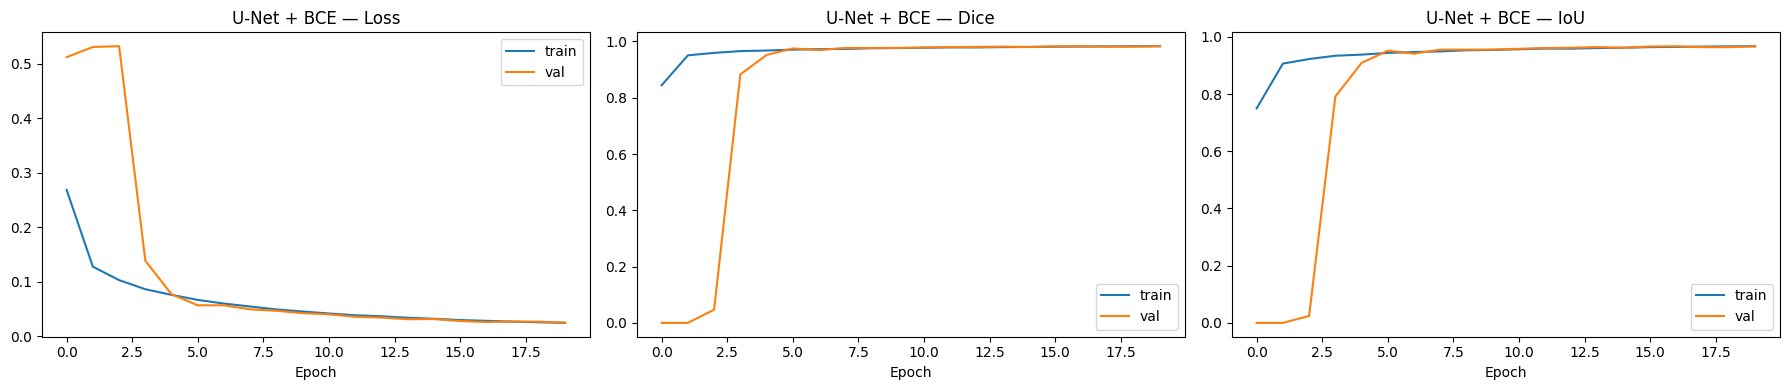

In [83]:
plot_history(history_bce, "U-Net + BCE")

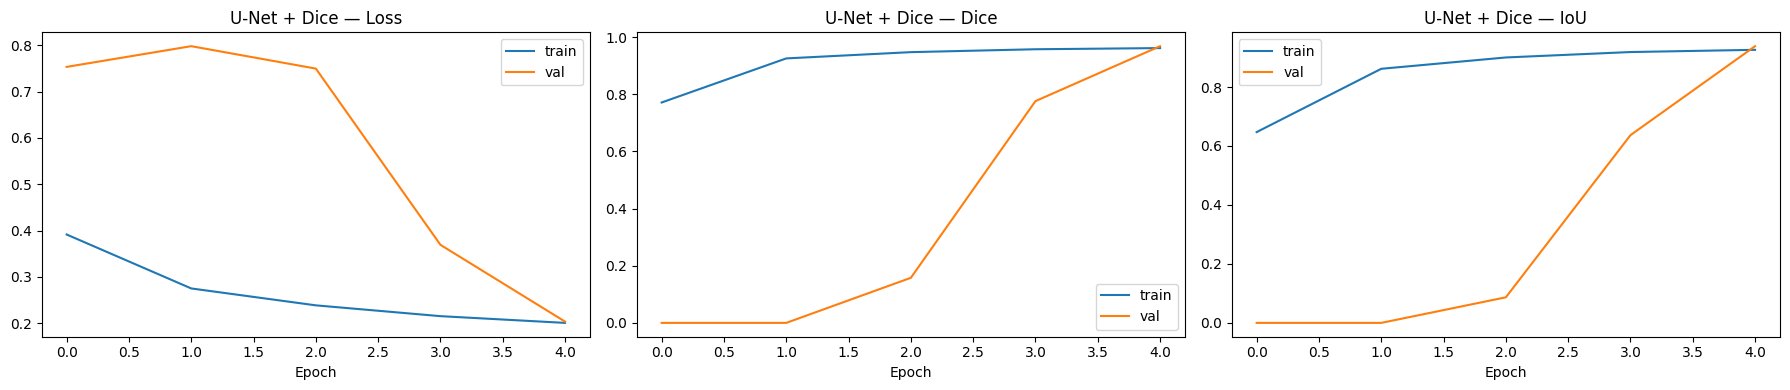

In [84]:
plot_history(history_dice, "U-Net + Dice")

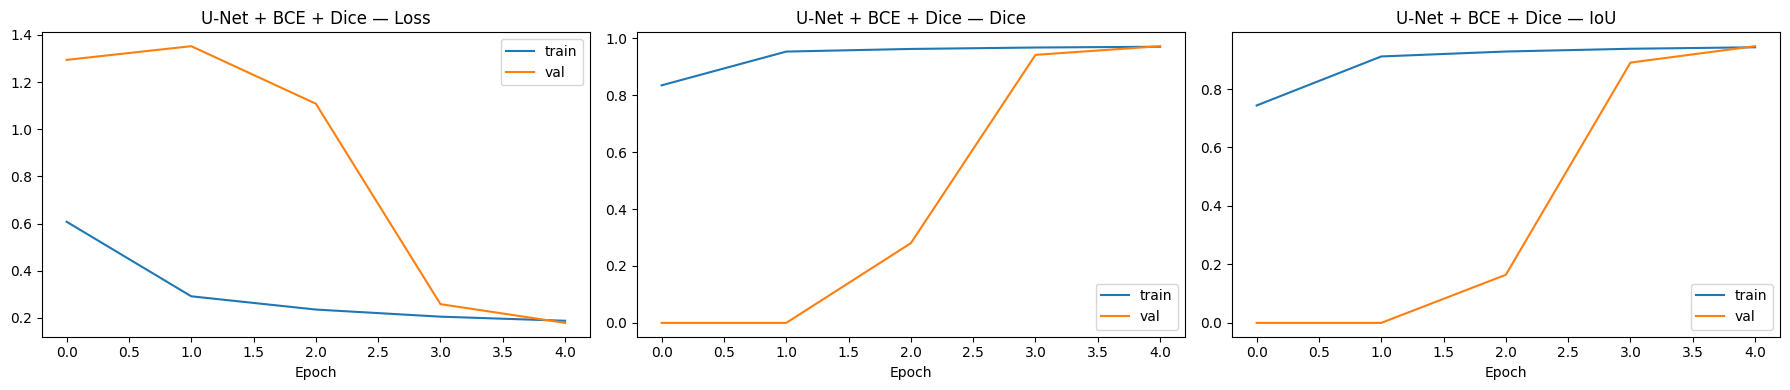

In [85]:
plot_history(history_combined, "U-Net + BCE + Dice")

сводная таблица

In [86]:
history_summary = summarize_histories({
    "BCE": history_bce,
    "Dice": history_dice,
    "BCE + Dice": history_combined
})
display(history_summary)

,model,best_val_loss,best_val_dice,best_val_iou
0,BCE,0.024948,0.983114,0.966793
2,BCE + Dice,0.178600,0.972539,0.946556
1,Dice,0.203414,0.968283,0.938527


оценка моделей на validation

In [87]:
results = [
    evaluate_model(model_bce, val_dataset, "U-Net + BCE"),
    evaluate_model(model_dice, val_dataset, "U-Net + Dice"),
    evaluate_model(model_combined, val_dataset, "U-Net + BCE + Dice"),
]
results_df = pd.DataFrame(results).sort_values("dice_coef", ascending=False)
display(results_df)


,model,loss,dice_coef,iou_coef
0,U-Net + BCE,0.024948,9.829219e-01,9.664235e-01
1,U-Net + Dice,0.753174,3.673846e-11,3.673846e-11
2,U-Net + BCE + Dice,1.294343,3.673846e-11,3.673846e-11


визуализация предсказаний лучшей модели

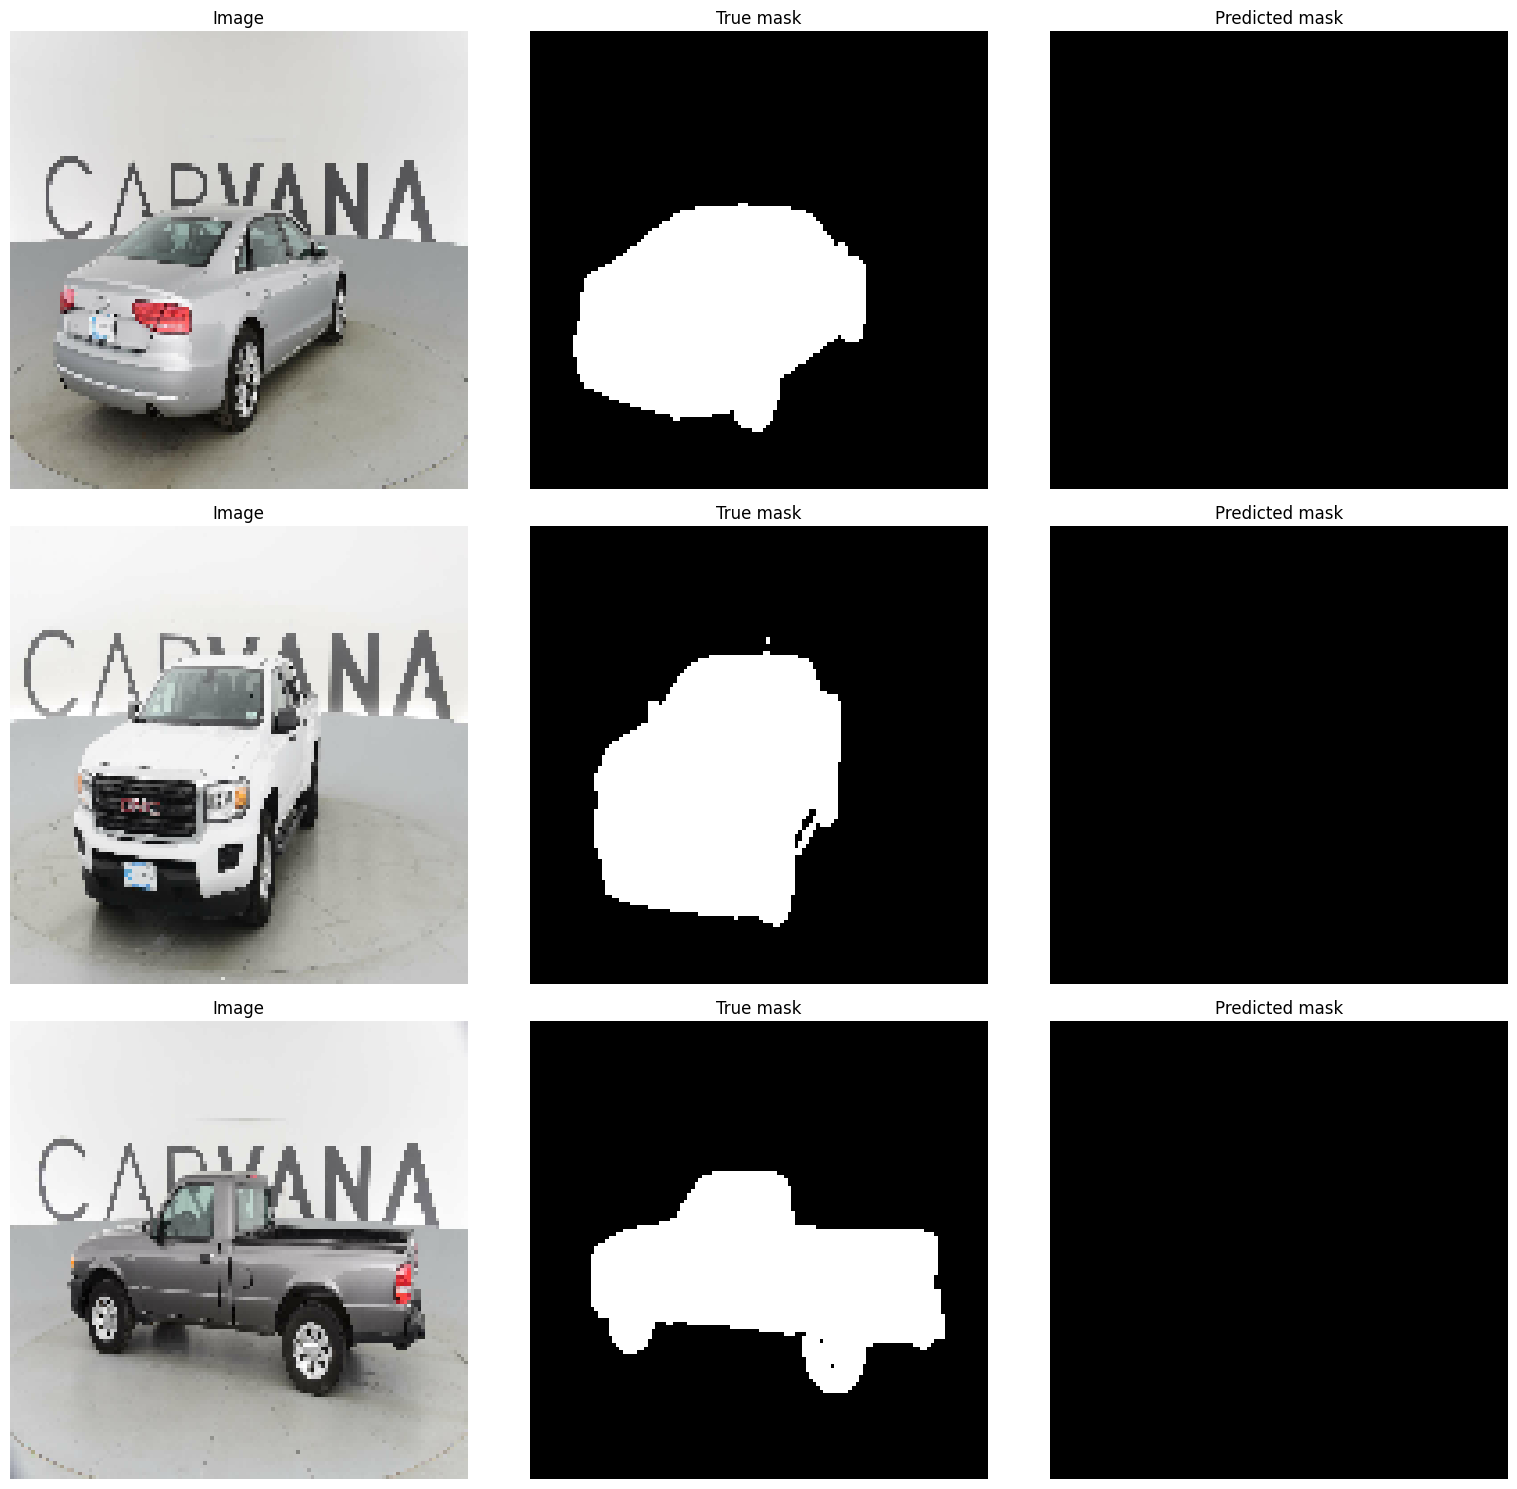

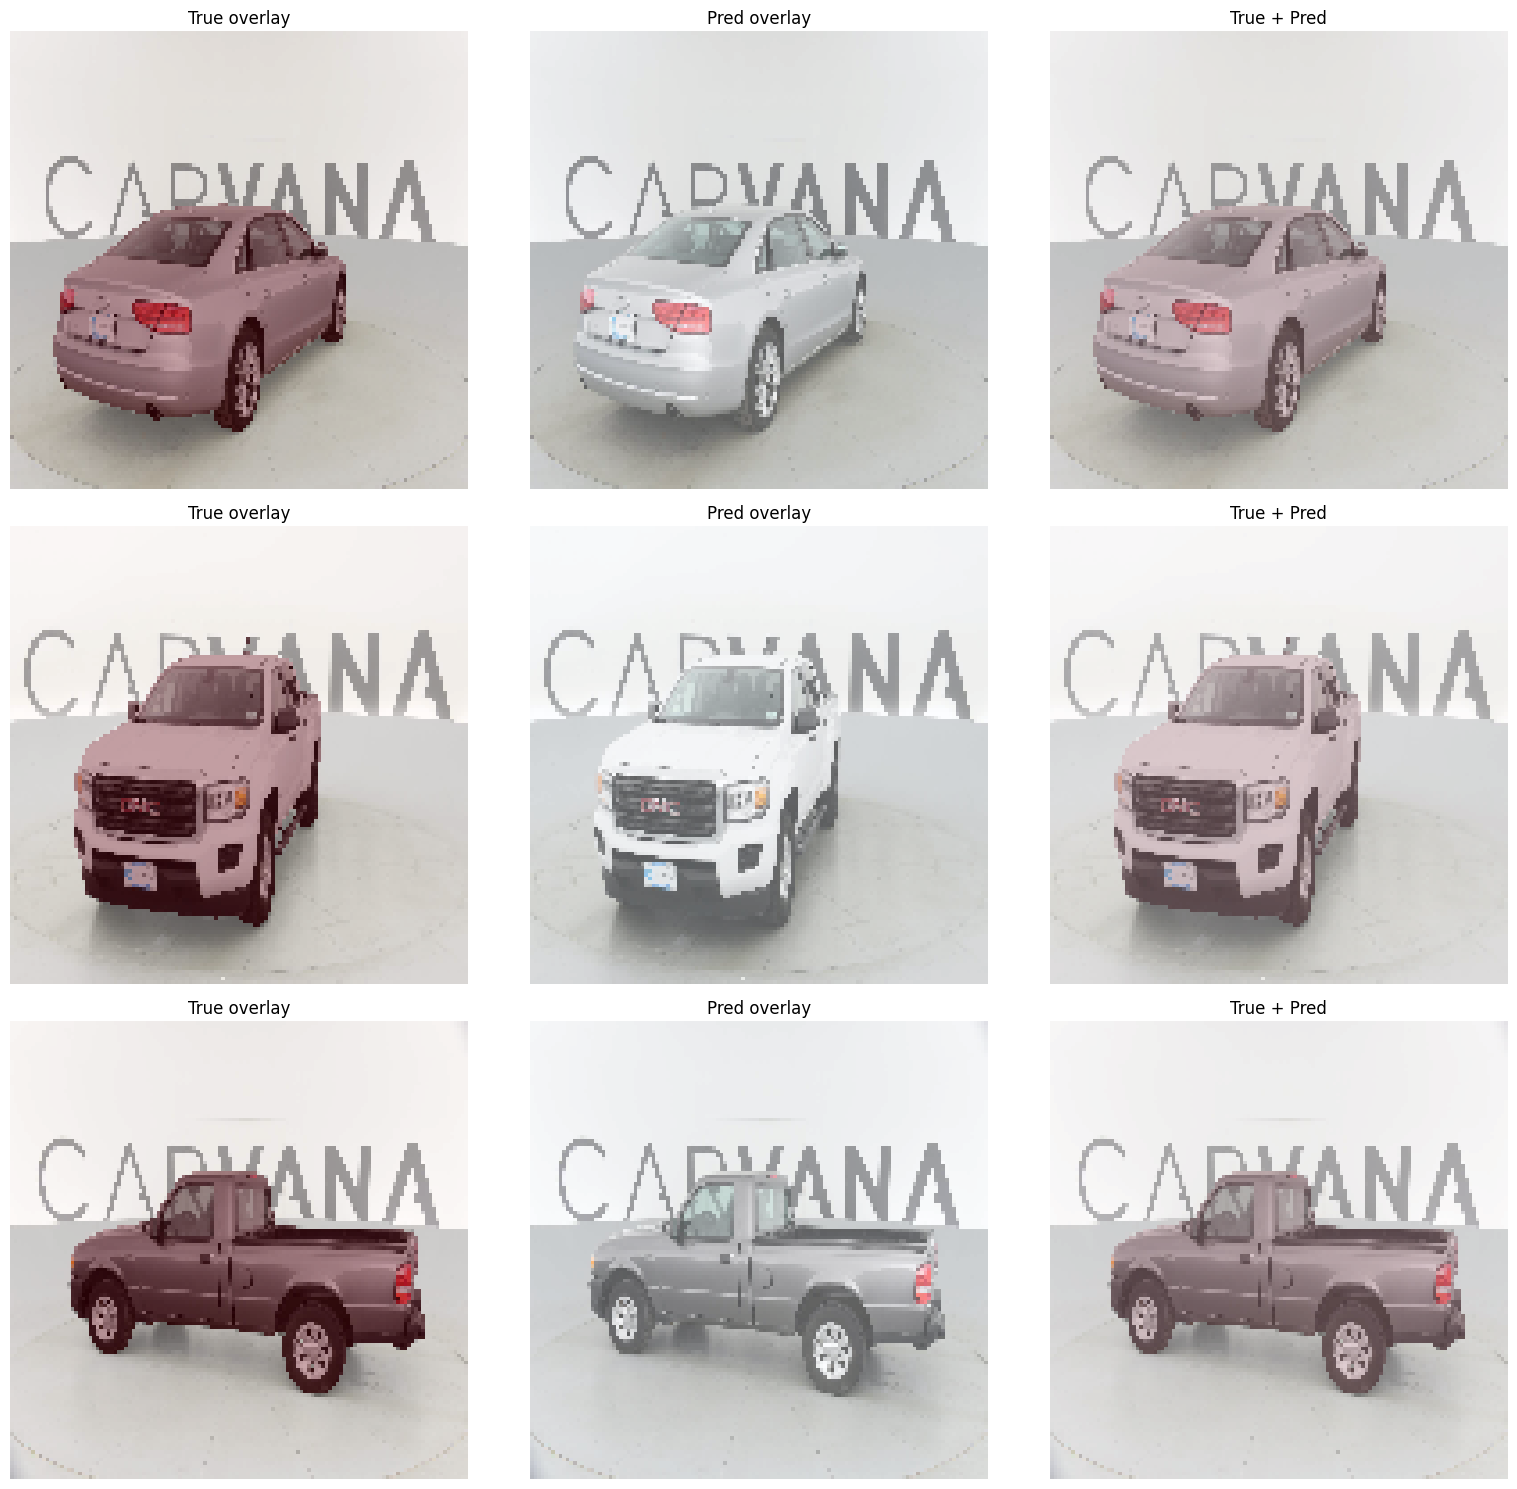

In [88]:
best_model = model_combined
show_predictions(best_model, val_dataset, n=3)
show_overlay_predictions(best_model, val_dataset, n=3)

АНАЛИЗ ОШИБОК МОДЕЛЕЙ

In [107]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

def show_errors(model, dataset, n=5, title=""):
    plt.figure(figsize=(18, 4.5 * n))
    if title:
        plt.suptitle(title, fontsize=16, y=0.98)
    
    for i, (image, mask) in enumerate(dataset.take(n)):
        # Предсказание
        img_single = image[0:1]  # (1, H, W, 3)
        pred = model.predict(img_single, verbose=0)[0, ..., 0]   # (H, W)
        pred_bin = (pred > 0.5).astype(np.float32)
        
        # Маска -> numpy
        true_mask = mask[0].numpy() if tf.is_tensor(mask[0]) else mask[0]
        if len(true_mask.shape) == 3:           # если 3-канальная
            true_mask = true_mask[..., 0]
        true_mask = (true_mask > 0.5).astype(np.float32)
        
        # IoU
        iou = np.sum(pred_bin * true_mask) / (np.sum(pred_bin) + np.sum(true_mask) + 1e-6)
        
        # Карта ошибок
        error = np.zeros((*pred.shape, 3))
        error[..., 0] = (pred_bin == 1) & (true_mask == 0)   # FP — красный
        error[..., 1] = (pred_bin == 1) & (true_mask == 1)   # TP — зелёный
        error[..., 2] = (pred_bin == 0) & (true_mask == 1)   # FN — синий
        
        # Визуализация
        plt.subplot(n, 4, i*4 + 1)
        plt.imshow(image[0].numpy() if tf.is_tensor(image[0]) else image[0])
        plt.title("Original")
        plt.axis('off')
        
        plt.subplot(n, 4, i*4 + 2)
        plt.imshow(true_mask, cmap='gray')
        plt.title("Ground Truth")
        plt.axis('off')
        
        plt.subplot(n, 4, i*4 + 3)
        plt.imshow(pred, cmap='gray', vmin=0, vmax=1)
        plt.title(f"Prediction\nIoU: {iou:.3f}")
        plt.axis('off')
        
        plt.subplot(n, 4, i*4 + 4)
        plt.imshow(error)
        plt.title("Errors\nRed=FP | Blue=FN | Green=TP")
        plt.axis('off')
    
    plt.tight_layout()
    plt.show()

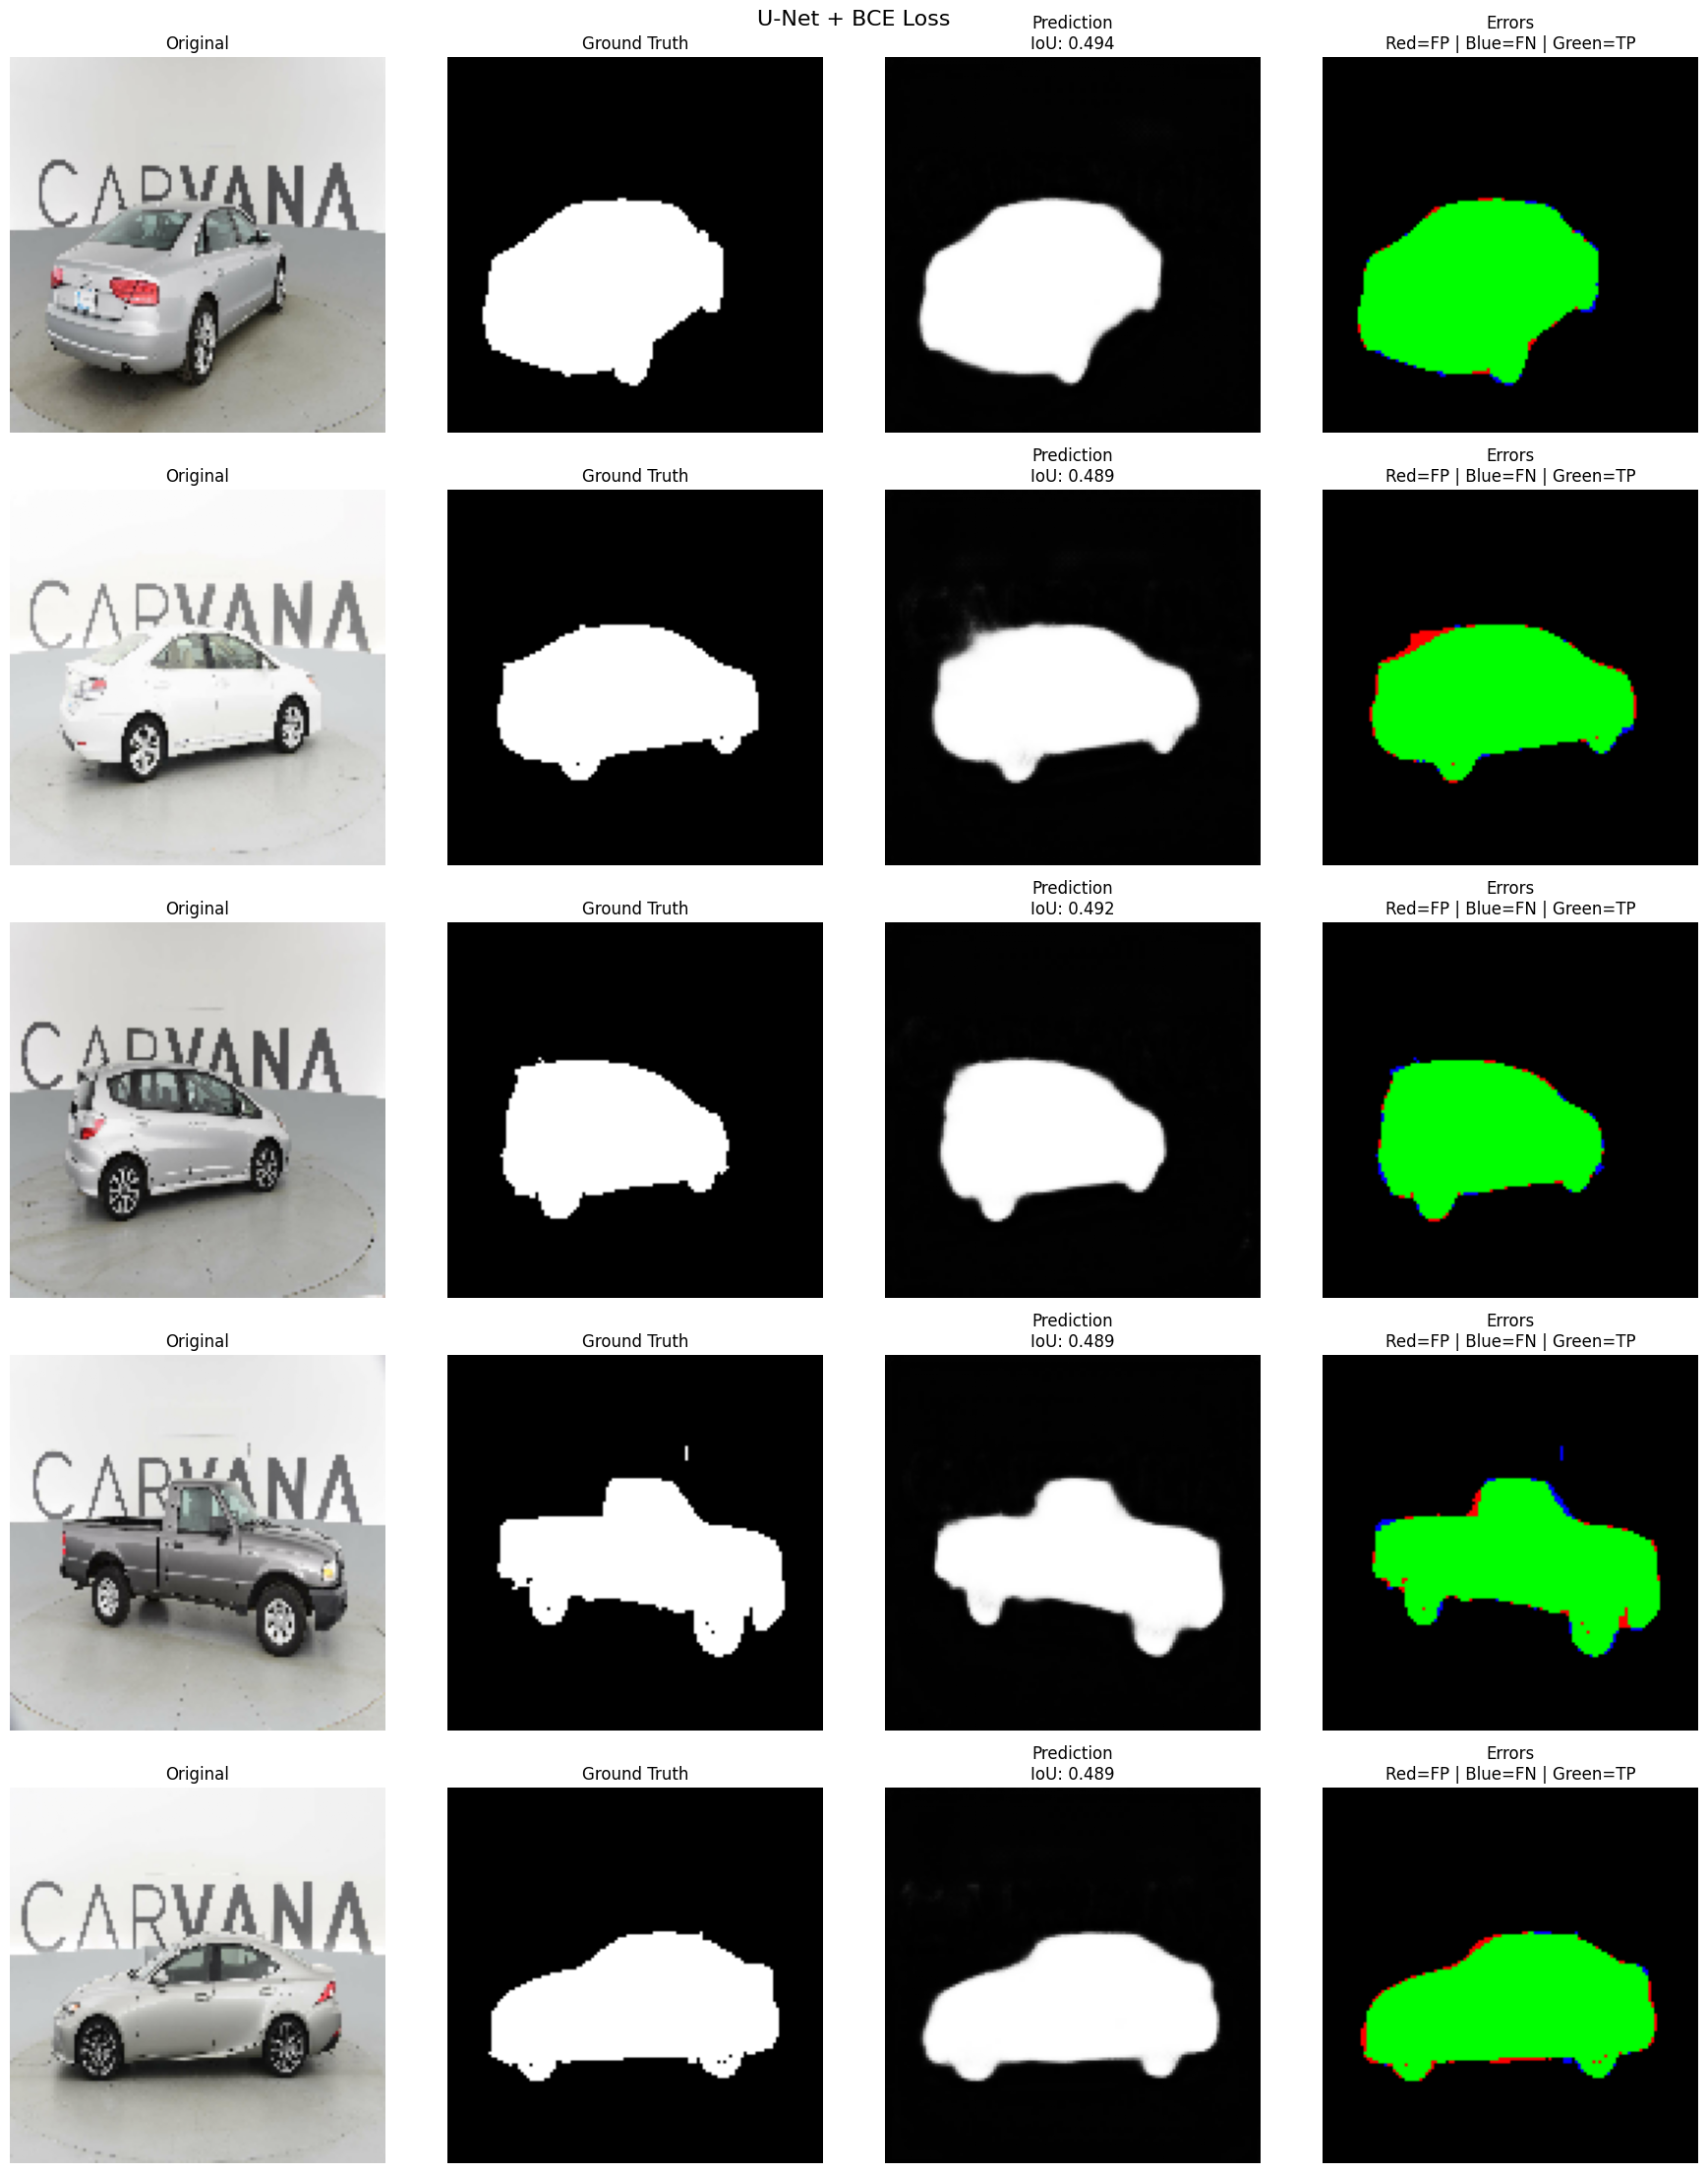

In [115]:
show_errors(model_bce, val_dataset, n=5, title="U-Net + BCE Loss")

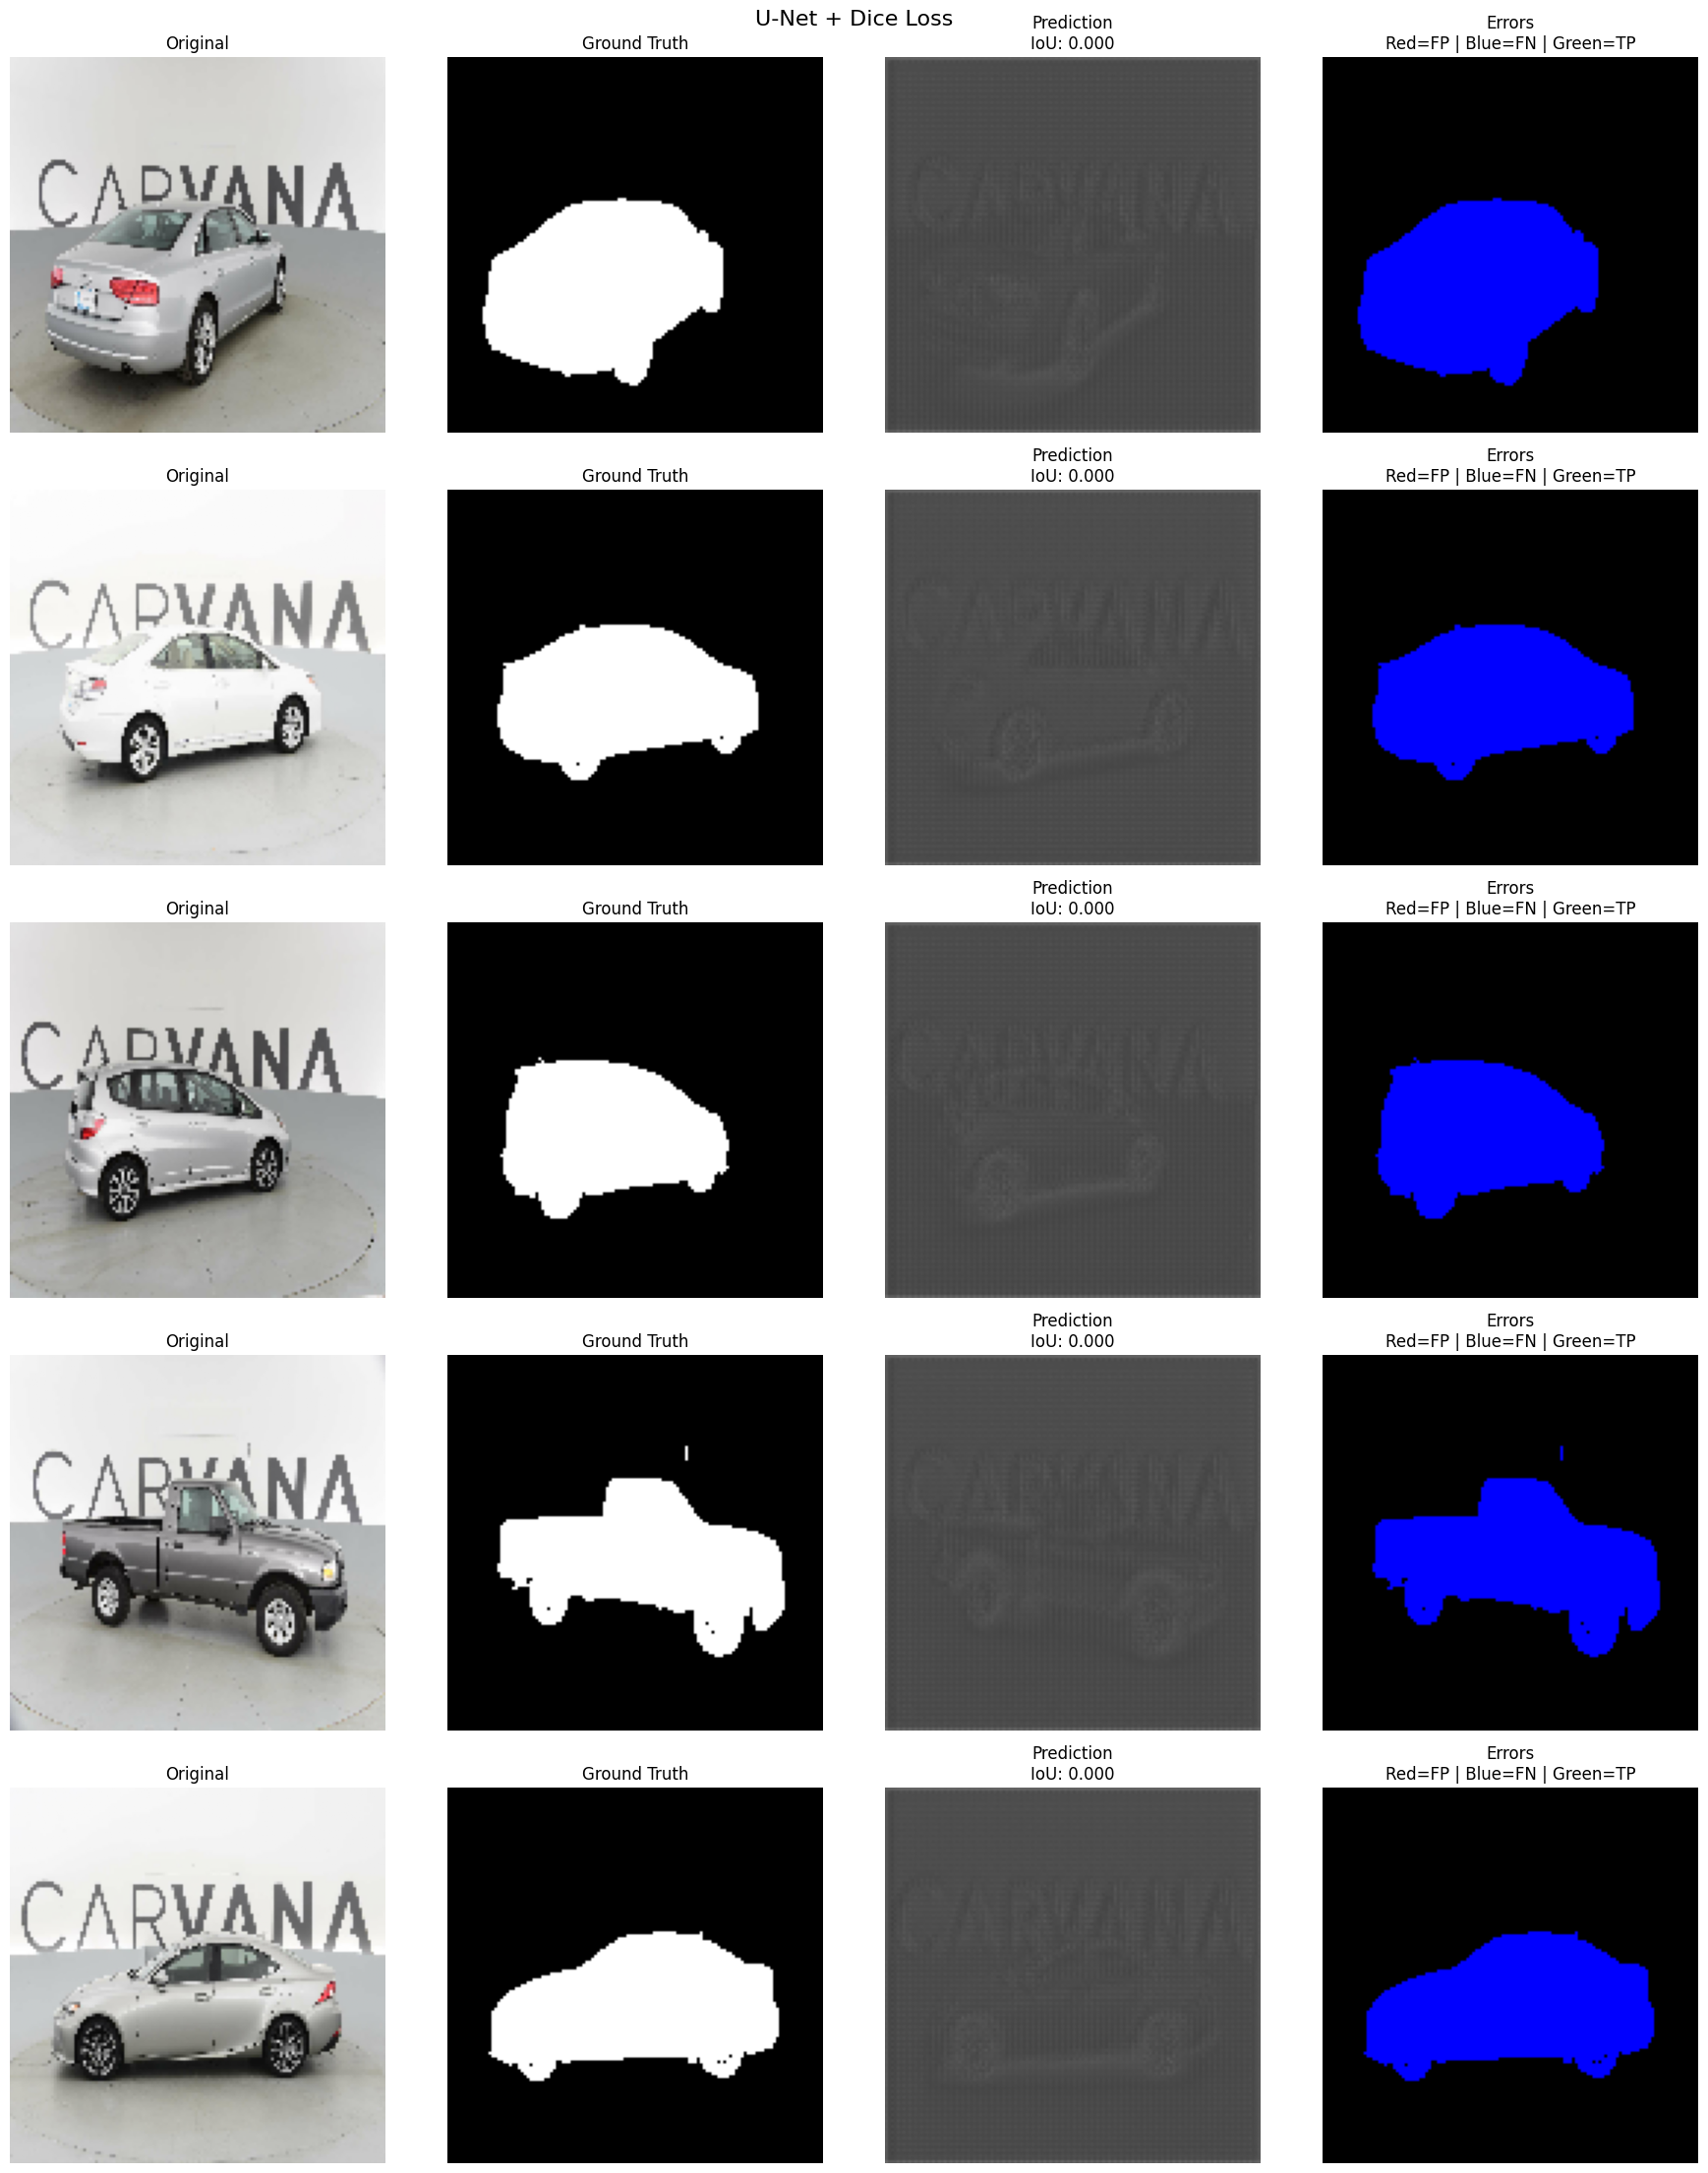

In [116]:
show_errors(model_dice, val_dataset, n=5, title="U-Net + Dice Loss")

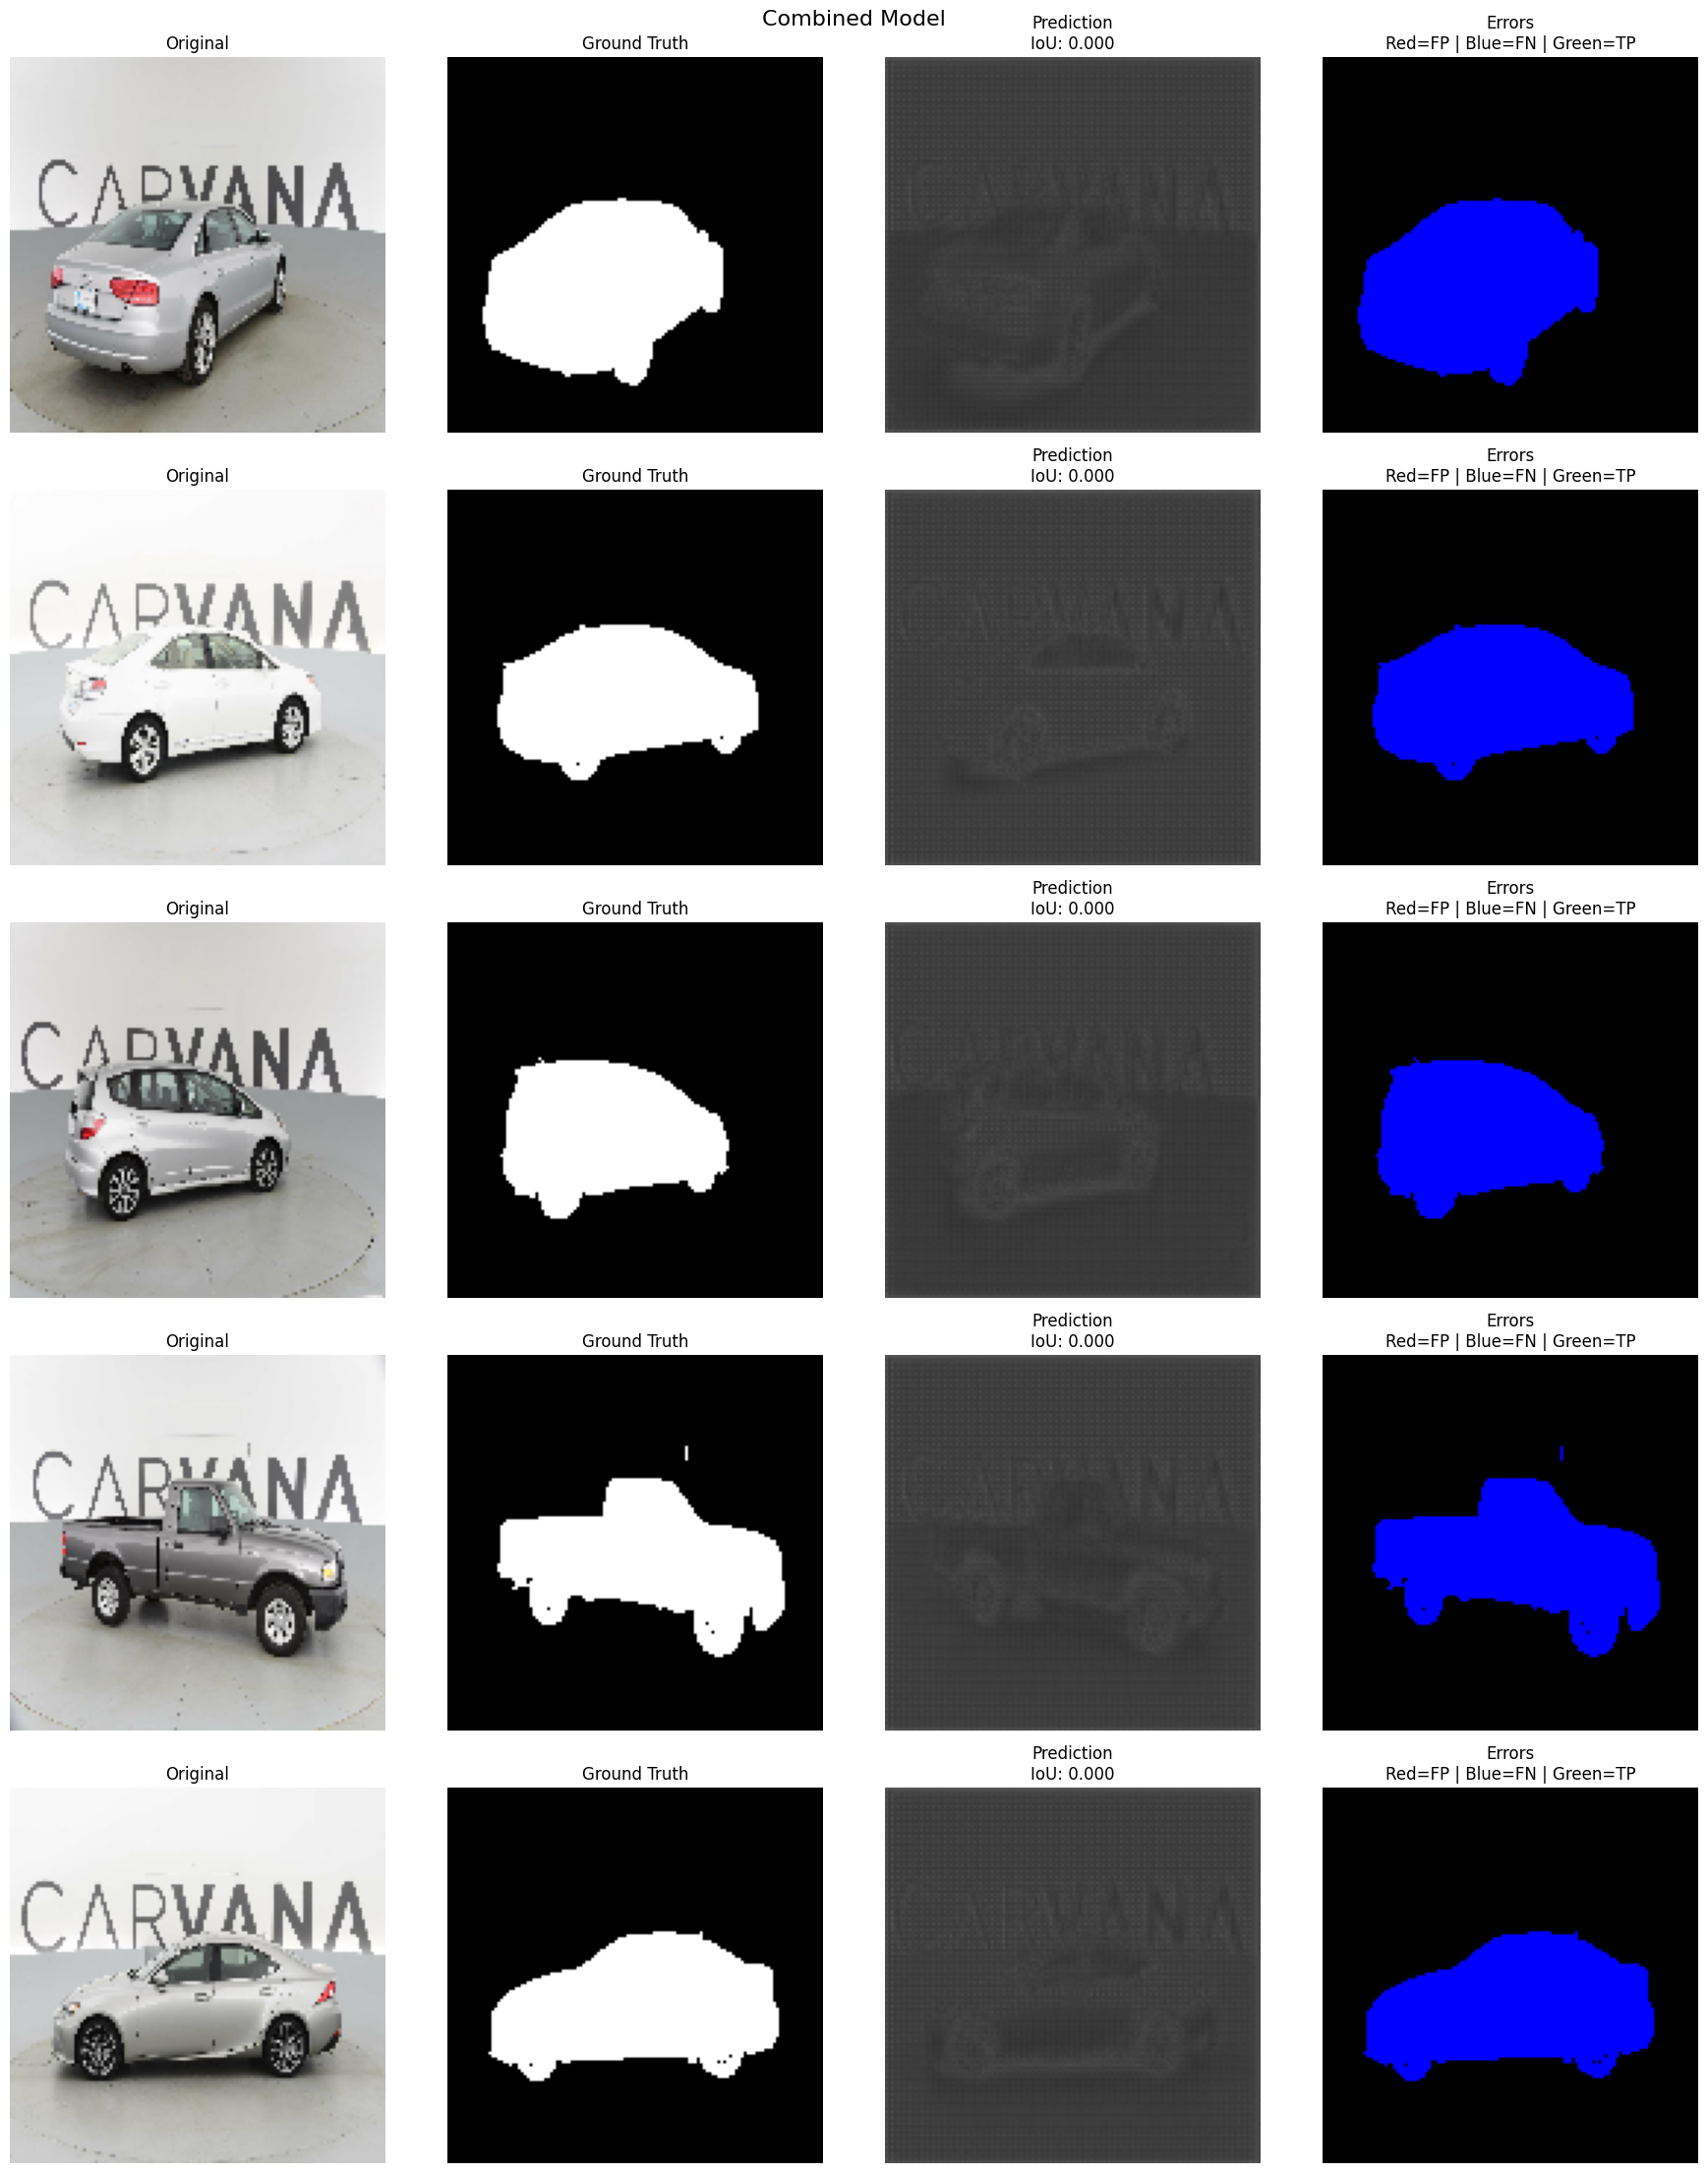

In [117]:
show_errors(model_combined, val_dataset, n=5, title="Combined Model")

### своя версия u-net

1) Увеличиваем входной размер до 512x512, чтобы сохранить больше деталей машины.
2) Для борьбы с однообразным фоном используем более сильную геометрическую аугментацию
   и архитектуру с dropout / residual-блоками.
3) Снижаем batch size, чтобы модель помещалась в память.

In [148]:
CUSTOM_IMG_SIZE = (256, 256)
CUSTOM_BATCH_SIZE = 2

In [159]:
def load_image_mask_hr(img_path, mask_path):

    # IMAGE
    image = tf.io.read_file(img_path)

    image = tf.image.decode_jpeg(
        image,
        channels=3
    )

    image = tf.image.resize(
        image,
        CUSTOM_IMG_SIZE
    )

    image = tf.cast(image, tf.float32) / 255.0


    # MASK (GIF)
    mask = tf.io.read_file(mask_path)

    # GIF -> берем первый frame
    mask = tf.image.decode_gif(mask)

    mask = mask[0]

    # оставляем 1 канал
    mask = mask[..., :1]

    mask = tf.image.resize(
        mask,
        CUSTOM_IMG_SIZE,
        method="nearest"
    )

    mask = tf.cast(mask, tf.float32) / 255.0

    mask = tf.where(mask > 0.5, 1.0, 0.0)

    return image, mask

In [160]:
custom_augmenter = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.05),
])

In [161]:
def augment_hr(image, mask):

    combined = tf.concat([image, mask], axis=-1)

    combined = custom_augmenter(
        combined,
        training=True
    )

    image = combined[..., :3]

    # строго один канал
    mask = combined[..., 3:]

    image = tf.image.random_brightness(
        image,
        max_delta=0.08
    )

    image = tf.image.random_contrast(
        image,
        lower=0.9,
        upper=1.1
    )

    image = tf.clip_by_value(image, 0.0, 1.0)

    mask = tf.where(mask > 0.5, 1.0, 0.0)

    return image, mask

In [162]:
def create_dataset_hr(images, masks, training=False):
    ds = tf.data.Dataset.from_tensor_slices((images, masks))
    ds = ds.map(load_image_mask_hr, num_parallel_calls=AUTOTUNE)

    if training:
        ds = ds.shuffle(512)
        ds = ds.map(augment_hr, num_parallel_calls=AUTOTUNE)

    ds = ds.batch(CUSTOM_BATCH_SIZE).prefetch(AUTOTUNE)
    return ds

In [163]:
train_dataset_hr = create_dataset_hr(train_images, train_masks, training=True)
val_dataset_hr = create_dataset_hr(val_images, val_masks, training=False)


In [164]:
def conv_block(x, filters, dropout=0.0):

    x = layers.Conv2D(filters, 3,
                      padding="same",
                      activation="relu")(x)

    x = layers.Conv2D(filters, 3,
                      padding="same",
                      activation="relu")(x)

    if dropout > 0:
        x = layers.Dropout(dropout)(x)

    return x

In [165]:
def build_custom_unet(input_shape=(256, 256, 3)):

    inputs = layers.Input(input_shape)

    # encoder
    c1 = conv_block(inputs, 16)
    p1 = layers.MaxPooling2D()(c1)

    c2 = conv_block(p1, 32, 0.05)
    p2 = layers.MaxPooling2D()(c2)

    c3 = conv_block(p2, 64, 0.1)
    p3 = layers.MaxPooling2D()(c3)

    # bottleneck
    bn = conv_block(p3, 128, 0.15)

    # decoder
    u1 = layers.Conv2DTranspose(64, 2,
                                strides=2,
                                padding="same")(bn)

    u1 = layers.Concatenate()([u1, c3])

    c4 = conv_block(u1, 64)

    u2 = layers.Conv2DTranspose(32, 2,
                                strides=2,
                                padding="same")(c4)

    u2 = layers.Concatenate()([u2, c2])

    c5 = conv_block(u2, 32)

    u3 = layers.Conv2DTranspose(16, 2,
                                strides=2,
                                padding="same")(c5)

    u3 = layers.Concatenate()([u3, c1])

    c6 = conv_block(u3, 16)

    outputs = layers.Conv2D(1, 1,
                            activation="sigmoid")(c6)

    return models.Model(inputs, outputs)

In [166]:
model_custom = build_custom_unet()
model_custom.compile(
    optimizer=tf.keras.optimizers.Adam(1e-4),
    loss=bce_dice_loss,
    metrics=[dice_coef, iou_coef]
)


In [167]:
callbacks_custom = [
    tf.keras.callbacks.EarlyStopping(
        patience=5,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        patience=3,
        factor=0.5
    )
]

In [168]:
history_custom = model_custom.fit(
    train_dataset_hr,
    validation_data=val_dataset_hr,
    epochs=20,
    callbacks=callbacks_custom
)


Epoch 1/20
480/480 ━━━━━━━━━━━━━━━━━━━━ 81s 162ms/step - dice_coef: 0.5492 - iou_coef: 0.4645 - loss: 0.6826 - val_dice_coef: 0.8837 - val_iou_coef: 0.7935 - val_loss: 0.2823 - learning_rate: 1.0000e-04
Epoch 2/20
480/480 ━━━━━━━━━━━━━━━━━━━━ 87s 178ms/step - dice_coef: 0.8983 - iou_coef: 0.8181 - loss: 0.2437 - val_dice_coef: 0.8846 - val_iou_coef: 0.7954 - val_loss: 0.2749 - learning_rate: 1.0000e-04
Epoch 3/20
480/480 ━━━━━━━━━━━━━━━━━━━━ 101s 207ms/step - dice_coef: 0.9263 - iou_coef: 0.8641 - loss: 0.1733 - val_dice_coef: 0.9484 - val_iou_coef: 0.9022 - val_loss: 0.1239 - learning_rate: 1.0000e-04
Epoch 4/20
480/480 ━━━━━━━━━━━━━━━━━━━━ 98s 200ms/step - dice_coef: 0.9454 - iou_coef: 0.8970 - loss: 0.1286 - val_dice_coef: 0.9613 - val_iou_coef: 0.9255 - val_loss: 0.0932 - learning_rate: 1.0000e-04
Epoch 5/20
480/480 ━━━━━━━━━━━━━━━━━━━━ 99s 201ms/step - dice_coef: 0.9542 - iou_coef: 0.9128 - loss: 0.1086 - val_dice_coef: 0.9608 - val_iou_coef: 0.9247 - val_loss: 0.0904 - learning_r

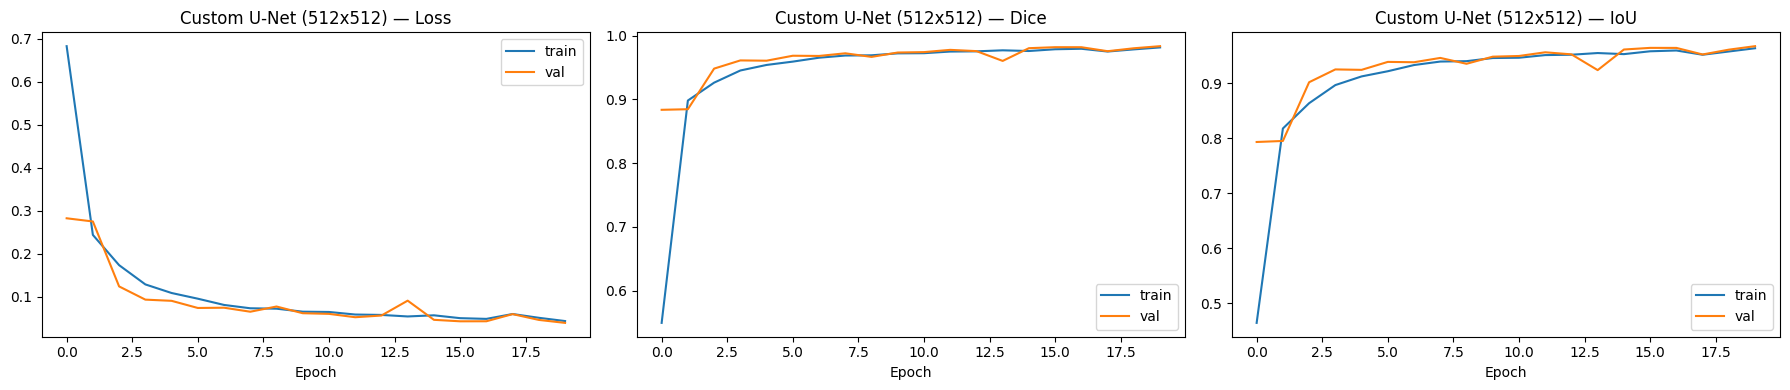

In [169]:
plot_history(history_custom, "Custom U-Net (512x512)")

In [170]:
custom_results = evaluate_model(model_custom, val_dataset_hr, "Custom U-Net + BCE + Dice")
custom_results_df = pd.DataFrame([custom_results])
display(custom_results_df)

,model,loss,dice_coef,iou_coef
0,Custom U-Net + BCE + Dice,0.039127,0.983635,0.967822


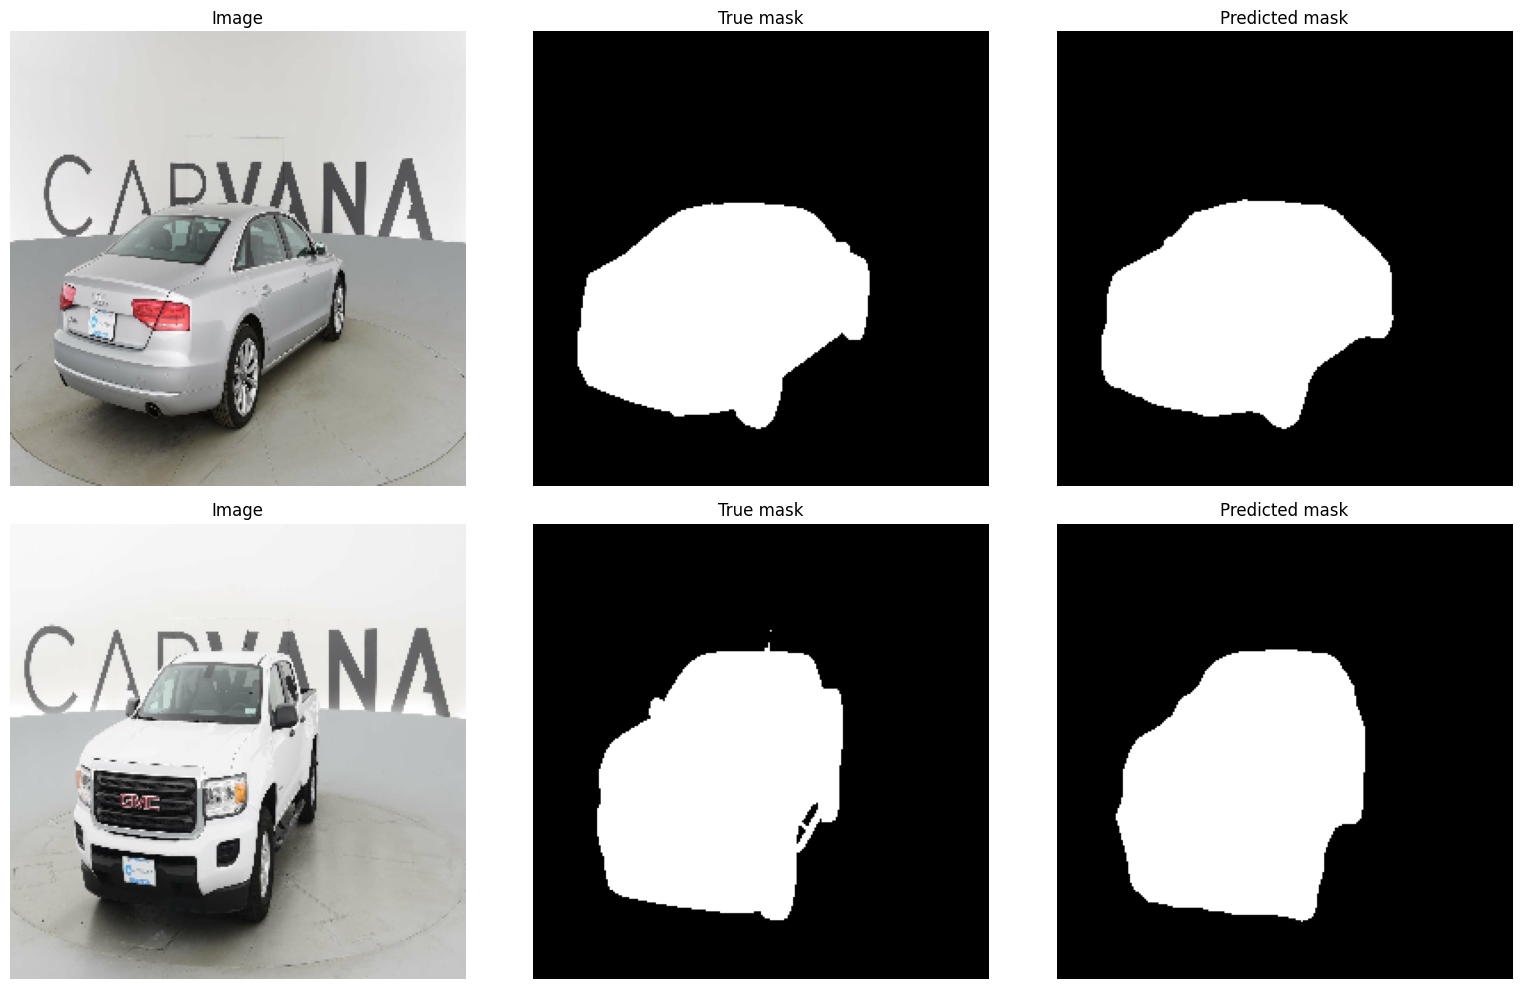

In [173]:
show_predictions(model_custom, val_dataset_hr, n=3)

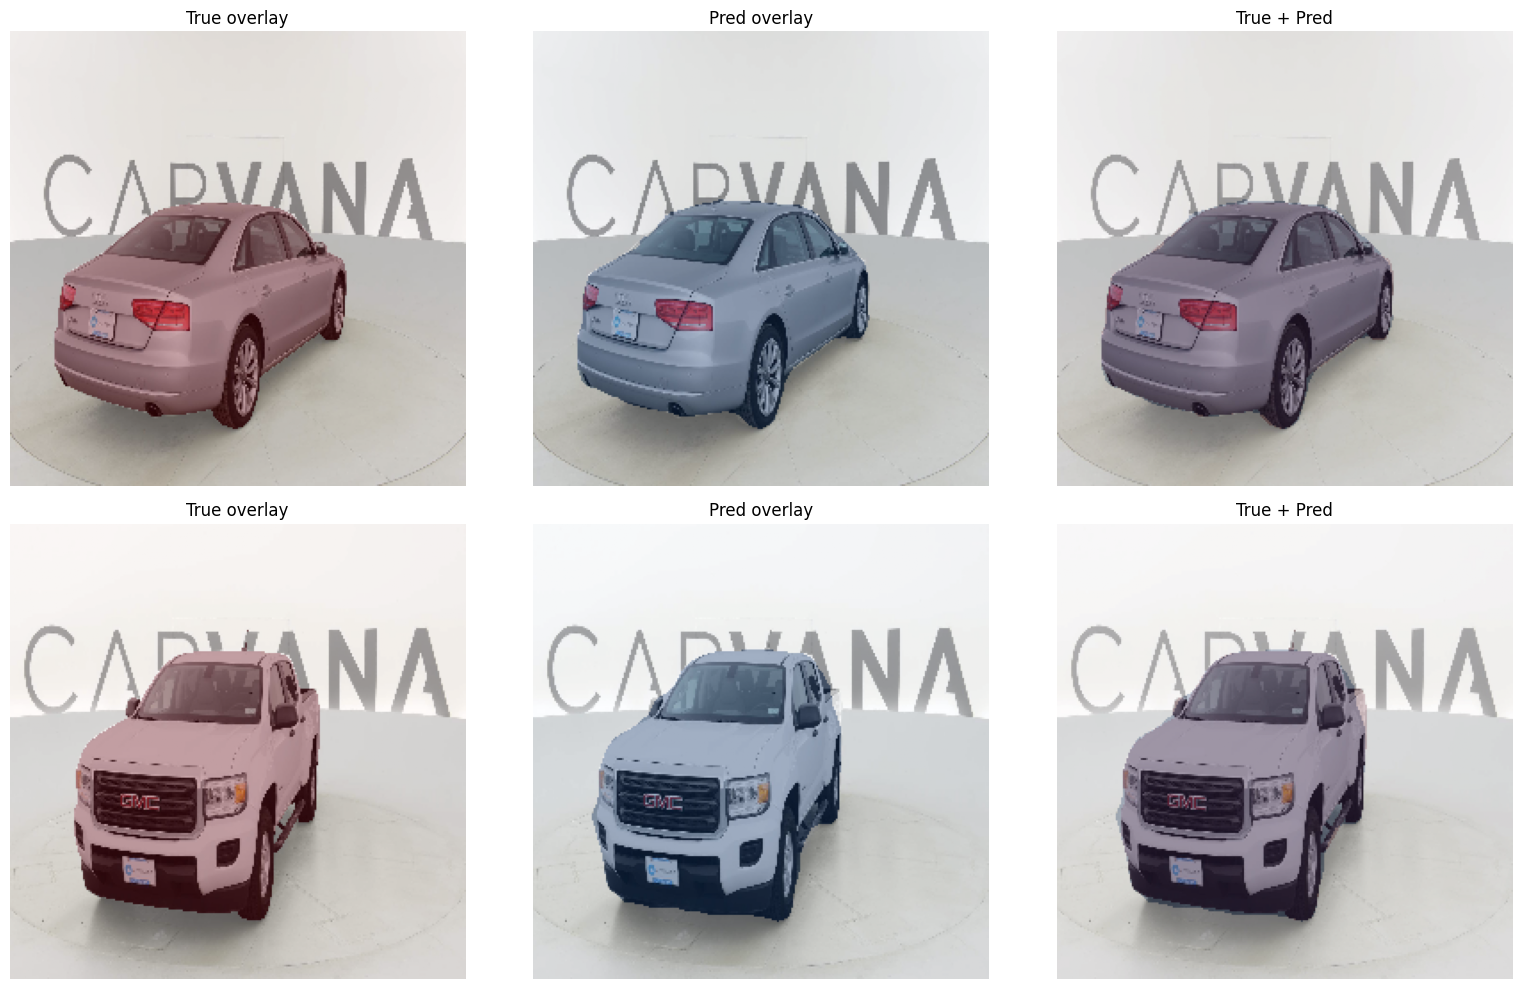

In [174]:
show_overlay_predictions(model_custom, val_dataset_hr, n=3)

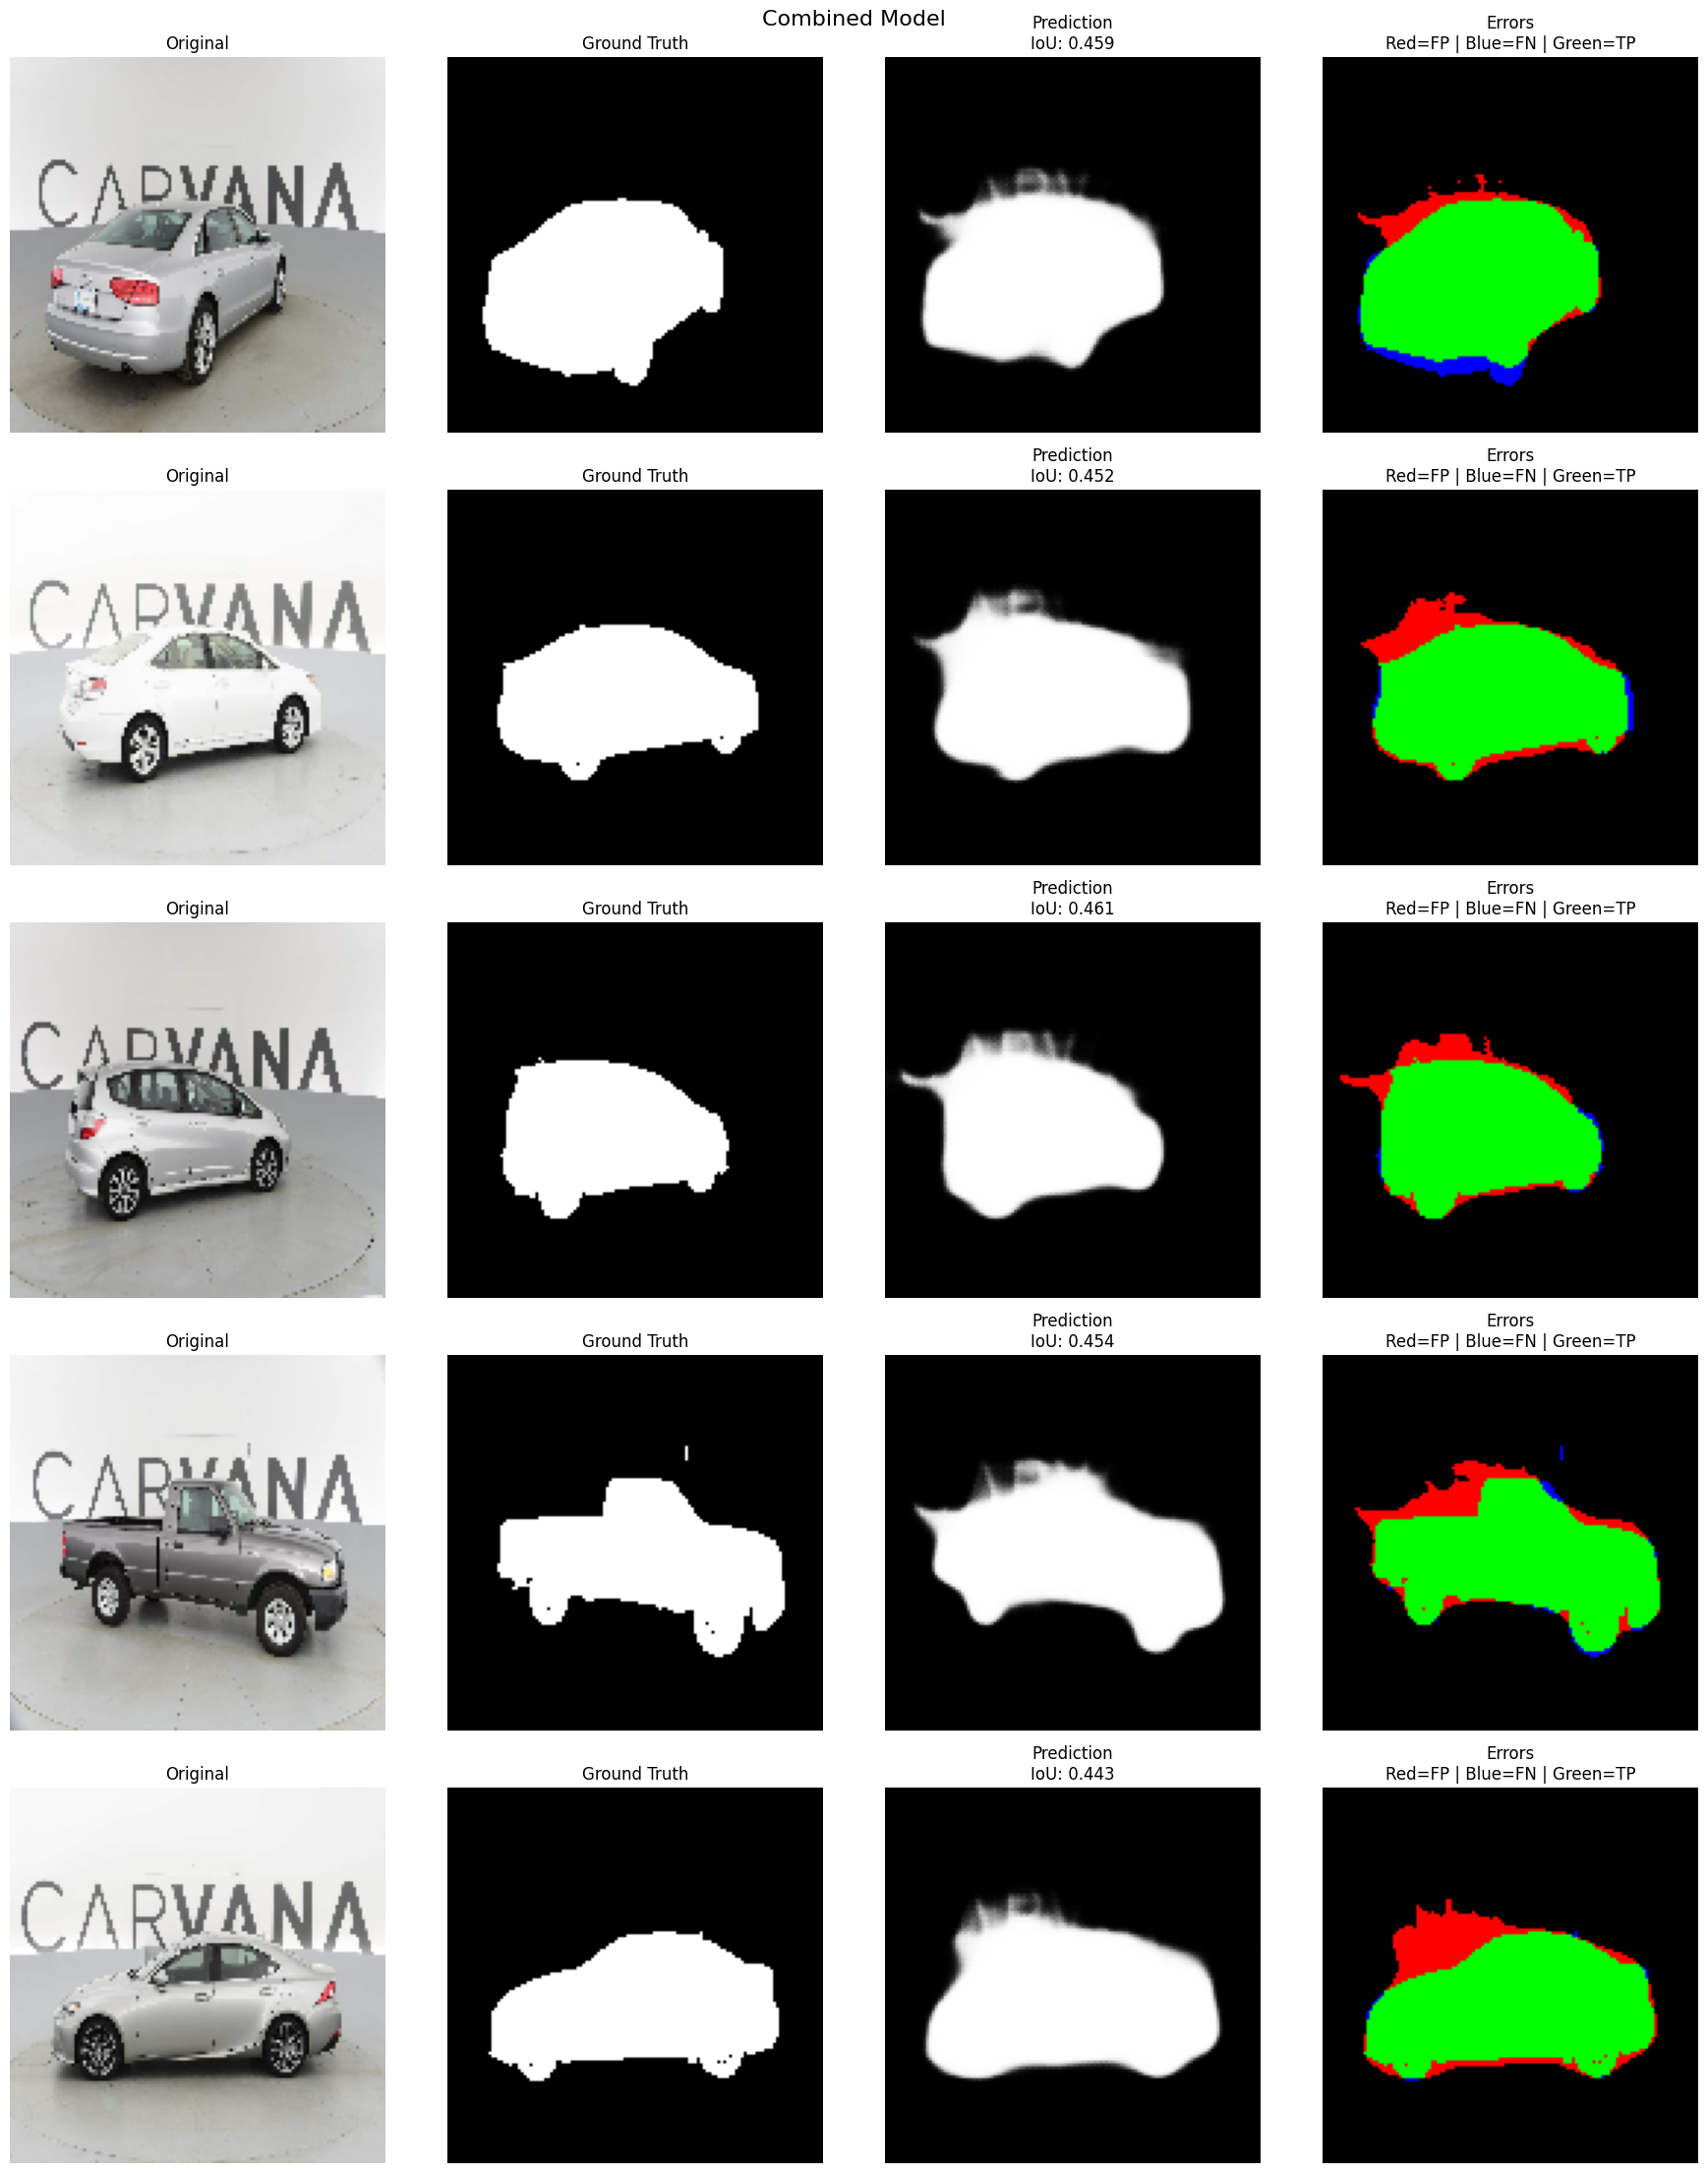

In [172]:
show_errors(model_custom, val_dataset, n=5, title="Combined Model")